# CLAM-TR v2: Complete Multi-Scale Analysis (Level 0 + Level 1)

This notebook implements multi-scale analysis for prostate cancer grading using:
- **Level 0 (20x)**: Cellular-level features
- **Level 1 (5x)**: Architectural/gland-level features

## Experiments
| # | Encoder | Level | Model | Purpose |
|---|---------|-------|-------|--------|
| 1-4 | ResNet-50/UNI | 0 (20x) | CLAM/CLAM-TR | Cellular scale |
| 5-8 | ResNet-50/UNI | 1 (5x) | CLAM/CLAM-TR | Architectural scale |

---
## Section 1: Setup & Configuration

In [1]:
# ============================================================
# INSTALL REQUIRED PACKAGES
# ============================================================
!pip install -q openslide-python timm scikit-learn pandas matplotlib seaborn tqdm
!apt-get install -q openslide-tools
!pip install -q transformers scikit-image
!pip install -q tifffile imagecodecs
!pip install -q huggingface_hub


Reading package lists...
Building dependency tree...
Reading state information...
The following additional packages will be installed:
  libopenslide0
Suggested packages:
  libtiff-tools
The following NEW packages will be installed:
  libopenslide0 openslide-tools
0 upgraded, 2 newly installed, 0 to remove and 41 not upgraded.
Need to get 104 kB of archives.
After this operation, 297 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 libopenslide0 amd64 3.4.1+dfsg-5build1 [89.8 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 openslide-tools amd64 3.4.1+dfsg-5build1 [13.8 kB]
Fetched 104 kB in 1s (107 kB/s)
Selecting previously unselected package libopenslide0.
(Reading database ... 121689 files and directories currently installed.)
Preparing to unpack .../libopenslide0_3.4.1+dfsg-5build1_amd64.deb ...
Unpacking libopenslide0 (3.4.1+dfsg-5build1) ...
Selecting previously unselected package openslide-tools.
Preparing to u

In [2]:
import os
import json
import time
import random
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (cohen_kappa_score, accuracy_score, f1_score,
                             precision_recall_fscore_support, confusion_matrix, roc_auc_score)
import openslide
import tifffile  # For correct TIFF pyramid reading

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

print(f'PyTorch: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')


Mounted at /content/drive
PyTorch: 2.9.0+cu126
CUDA available: True


In [3]:
# ============================================================================
# CONFIGURATION - MULTI-SCALE VERSION
# ============================================================================

CONFIG = {
    # Data paths
    'original_slides': '/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/train_images/',
    'ground_truth_masks': '/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/train_label_masks/',
    'subset_folder': '/content/drive/MyDrive/PANDA_Subset_600/images/',

    # Level 0 paths (existing)
    'preprocessing_dir': '/content/drive/MyDrive/CLAM_TR_Preprocessing/',
    'features_dir': '/content/drive/MyDrive/CLAM_TR_Features/',
    'checkpoints_dir': '/content/drive/MyDrive/CLAM_TR_Checkpoints/',
    'results_dir': '/content/drive/MyDrive/CLAM_TR_Results/',

    # Level 1 paths (NEW)
    'checkpoints_dir_level1': '/content/drive/MyDrive/CLAM_TR_Checkpoints/level1/',
    'results_dir_level1': '/content/drive/MyDrive/CLAM_TR_Results/level1/',

    # CSV path
    'csv_path': '/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/train.csv',

    # Preprocessing parameters
    'patch_size': 256,
    'magnification': '20x',  # Default magnification for Level 0
    'target_magnification': 20,  # Target magnification for preprocessing
    'default_K': 128,  # Default K for CLAM-TR
    'magnification_level0': '20x',
    'magnification_level1': '5x',

    # Model parameters
    'feature_dim': 1024,
    'hidden_dim': 512,
    'n_classes': 6,
    'dropout': 0.25,
    'K': 128,
    'num_heads': 8,
    'gamma_values': [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99],

    # Training parameters
    'epochs': 50,
    'lr': 1e-4,
    'weight_decay': 1e-5,
    'label_smoothing': 0.1,
    'seed': 42,
    'train_ratio': 0.8,
    'val_ratio': 0.2,

    # Checkpoint frequencies
    'checkpoint_freq_epochs': 5,
    'checkpoint_freq_minutes': 30,
    'preprocessing_checkpoint_freq': 50,
    'feature_extraction_checkpoint_freq': 100,

    # Level 1 specific
    'level1_max_tiles': 500,
    'level1_tissue_threshold': 0.90,
}

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG['seed'])
print(f'Seeds set to {CONFIG["seed"]}')


Seeds set to 42


In [4]:
# ============================================================================
# HUGGINGFACE AUTHENTICATION (Required for UNI encoder)
# ============================================================================
# Replace 'YOUR_HF_TOKEN_HERE' with your actual HuggingFace token
# Get your token at: https://huggingface.co/settings/tokens

import os
from huggingface_hub import login

HF_TOKEN = "hf_YOUR_HF_TOKEN_HERE"  # <-- REPLACE WITH YOUR TOKEN

# Set environment variable
os.environ["HF_TOKEN"] = HF_TOKEN
os.environ["HUGGINGFACE_HUB_TOKEN"] = HF_TOKEN

# Authenticate with HuggingFace
try:
    login(token=HF_TOKEN, add_to_git_credential=False)
    print("HuggingFace authentication successful!")
    print("You can now access gated models like MahmoodLab/UNI")
except Exception as e:
    print(f"HuggingFace authentication failed: {e}")
    print("\nTo fix this:")
    print("1. Go to https://huggingface.co/settings/tokens")
    print("2. Create a new token with 'read' access")
    print("3. Replace 'YOUR_HF_TOKEN_HERE' with your token")
    print("4. Make sure you have access to MahmoodLab/UNI")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


HuggingFace authentication successful!
You can now access gated models like MahmoodLab/UNI


In [5]:
# ============================================================
# ABLATION STUDY CONFIGURATIONS
# ============================================================
# This defines 7 preprocessing configurations to test which
# techniques improve CLAM-TR performance on Level 1 data.
# ============================================================

ABLATION_CONFIGS = {
    'P0_base': {
        'name': 'P0_base',
        'description': 'Base: tifffile + BGR->RGB + darkest selection',
        'patches_folder': 'patches_L1_P0_base',
        'coords_folder': 'coords_L1/P0_base',
        'features_folder': 'L1_P0_base',
        'checkpoints_folder': 'level1/P0_base',
        'results_folder': 'level1/P0_base',

        # Base settings
        'tile_size': 256,
        'max_tiles': 200,
        'white_threshold': 0.95,
        'mode': 0,

        # Optional features (all OFF for base)
        'provider_specific': False,
        'artifact_filter': False,
        'tissue_scoring': False,
    },

    'P1_threshold': {
        'name': 'P1_threshold',
        'description': 'P0 + better threshold (0.90) + more tiles (500)',
        'patches_folder': 'patches_L1_P1_threshold',
        'coords_folder': 'coords_L1/P1_threshold',
        'features_folder': 'L1_P1_threshold',
        'checkpoints_folder': 'level1/P1_threshold',
        'results_folder': 'level1/P1_threshold',

        'tile_size': 256,
        'max_tiles': 500,           # CHANGED
        'white_threshold': 0.90,    # CHANGED
        'mode': 0,

        'provider_specific': False,
        'artifact_filter': False,
        'tissue_scoring': False,
    },

    'P2_provider': {
        'name': 'P2_provider',
        'description': 'P0 + provider-specific tile sizes',
        'patches_folder': 'patches_L1_P2_provider',
        'coords_folder': 'coords_L1/P2_provider',
        'features_folder': 'L1_P2_provider',
        'checkpoints_folder': 'level1/P2_provider',
        'results_folder': 'level1/P2_provider',

        'tile_size': 256,
        'tile_size_karolinska': 192,  # NEW
        'tile_size_radboud': 256,     # NEW
        'max_tiles': 200,
        'white_threshold': 0.95,
        'mode': 0,

        'provider_specific': True,    # CHANGED
        'artifact_filter': False,
        'tissue_scoring': False,
    },

    'P3_mode2': {
        'name': 'P3_mode2',
        'description': 'P0 + Mode 2 (shifted grid for TTA)',
        'patches_folder': 'patches_L1_P3_mode2',
        'coords_folder': 'coords_L1/P3_mode2',
        'features_folder': 'L1_P3_mode2',
        'checkpoints_folder': 'level1/P3_mode2',
        'results_folder': 'level1/P3_mode2',

        'tile_size': 256,
        'max_tiles': 200,
        'white_threshold': 0.95,
        'mode': 2,                    # CHANGED - shifted grid

        'provider_specific': False,
        'artifact_filter': False,
        'tissue_scoring': False,
    },

    'P4_artifact': {
        'name': 'P4_artifact',
        'description': 'P0 + artifact filtering (pen marks, bubbles)',
        'patches_folder': 'patches_L1_P4_artifact',
        'coords_folder': 'coords_L1/P4_artifact',
        'features_folder': 'L1_P4_artifact',
        'checkpoints_folder': 'level1/P4_artifact',
        'results_folder': 'level1/P4_artifact',

        'tile_size': 256,
        'max_tiles': 200,
        'white_threshold': 0.95,
        'mode': 0,

        'provider_specific': False,
        'artifact_filter': True,      # CHANGED
        'pen_threshold': 0.05,        # Max 5% very dark pixels
        'bubble_threshold': 0.10,     # Max 10% very bright in center
        'tissue_scoring': False,
    },

    'P5_tissue_score': {
        'name': 'P5_tissue_score',
        'description': 'P0 + tissue content scoring (not just darkness)',
        'patches_folder': 'patches_L1_P5_tissue_score',
        'coords_folder': 'coords_L1/P5_tissue_score',
        'features_folder': 'L1_P5_tissue_score',
        'checkpoints_folder': 'level1/P5_tissue_score',
        'results_folder': 'level1/P5_tissue_score',

        'tile_size': 256,
        'max_tiles': 200,
        'white_threshold': 0.95,
        'mode': 0,

        'provider_specific': False,
        'artifact_filter': False,
        'tissue_scoring': True,       # CHANGED
    },

    'P6_combined': {
        'name': 'P6_combined',
        'description': 'All improvements combined',
        'patches_folder': 'patches_L1_P6_combined',
        'coords_folder': 'coords_L1/P6_combined',
        'features_folder': 'L1_P6_combined',
        'checkpoints_folder': 'level1/P6_combined',
        'results_folder': 'level1/P6_combined',

        'tile_size': 256,
        'tile_size_karolinska': 192,
        'tile_size_radboud': 256,
        'max_tiles': 500,
        'white_threshold': 0.90,
        'mode': 0,

        'provider_specific': True,
        'artifact_filter': True,
        'pen_threshold': 0.05,
        'bubble_threshold': 0.10,
        'tissue_scoring': True,
    },
}

# ============================================================
# HELPER FUNCTIONS FOR PATHS
# ============================================================

# Local disk base for fast processing
LOCAL_BASE = '/content/local_patches'

def get_patches_dir(config_name):
    """Get patches directory for specific ablation config (Google Drive)."""
    config = ABLATION_CONFIGS[config_name]
    return os.path.join(CONFIG['preprocessing_dir'], config['patches_folder'])

def get_coords_dir(config_name):
    """Get coordinates directory for specific ablation config (Google Drive)."""
    config = ABLATION_CONFIGS[config_name]
    return os.path.join(CONFIG['preprocessing_dir'], config['coords_folder'])

def get_features_dir(config_name, encoder):
    """Get features directory for specific ablation config and encoder."""
    config = ABLATION_CONFIGS[config_name]
    return os.path.join(CONFIG['features_dir'], config['features_folder'], encoder)

def get_checkpoints_dir(config_name):
    """Get checkpoints directory for specific ablation config."""
    config = ABLATION_CONFIGS[config_name]
    return os.path.join(CONFIG['checkpoints_dir'], config['checkpoints_folder'])

def get_results_dir(config_name):
    """Get results directory for specific ablation config."""
    config = ABLATION_CONFIGS[config_name]
    return os.path.join(CONFIG['results_dir'], config['results_folder'])

def get_local_patches_dir(config_name):
    """Get LOCAL patches directory for fast processing."""
    config = ABLATION_CONFIGS[config_name]
    return os.path.join(LOCAL_BASE, config['patches_folder'])

def get_local_coords_dir(config_name):
    """Get LOCAL coords directory for fast processing."""
    config = ABLATION_CONFIGS[config_name]
    return os.path.join(LOCAL_BASE, config['coords_folder'])

print(f"Ablation configs defined: {list(ABLATION_CONFIGS.keys())}")


Ablation configs defined: ['P0_base', 'P1_threshold', 'P2_provider', 'P3_mode2', 'P4_artifact', 'P5_tissue_score', 'P6_combined']


In [6]:
# GPU Detection and Batch Size Configuration
def detect_gpu_and_set_batch_size():
    if torch.cuda.is_available():
        gpu_name = torch.cuda.get_device_name(0)
        gpu_memory = torch.cuda.get_device_properties(0).total_memory / 1e9
        print(f'GPU: {gpu_name}')
        print(f'Memory: {gpu_memory:.1f} GB')

        if 'A100' in gpu_name:
            batch_sizes = {'feature_extraction': 256, 'training': 1}
        elif 'V100' in gpu_name or gpu_memory >= 15:
            batch_sizes = {'feature_extraction': 128, 'training': 1}
        elif 'T4' in gpu_name or gpu_memory >= 14:
            batch_sizes = {'feature_extraction': 64, 'training': 1}
        else:
            batch_sizes = {'feature_extraction': 32, 'training': 1}
        return 'cuda', batch_sizes
    return 'cpu', {'feature_extraction': 16, 'training': 1}

DEVICE, BATCH_SIZES = detect_gpu_and_set_batch_size()
print(f'Device: {DEVICE}')
print(f'Batch sizes: {BATCH_SIZES}')

GPU: Tesla T4
Memory: 15.8 GB
Device: cuda
Batch sizes: {'feature_extraction': 128, 'training': 1}


---
## Section 2: Directory Setup

In [7]:
def create_all_directories():
    """Create all directories including ablation study folders."""

    # Level 0 directories (existing)
    level0_dirs = [
        CONFIG['preprocessing_dir'],
        os.path.join(CONFIG['preprocessing_dir'], 'patches'),
        os.path.join(CONFIG['preprocessing_dir'], 'coordinates'),
        CONFIG['features_dir'],
        os.path.join(CONFIG['features_dir'], 'resnet50'),
        os.path.join(CONFIG['features_dir'], 'uni'),
        CONFIG['checkpoints_dir'],
        CONFIG['results_dir'],
        os.path.join(CONFIG['results_dir'], 'visualizations'),
        os.path.join(CONFIG['results_dir'], 'models'),

        # Level 1 (existing legacy paths)
    ]

    for d in level0_dirs:
        os.makedirs(d, exist_ok=True)

    print("Level 0 and legacy Level 1 directories created")

    # NEW: Create directories for ALL ablation configs
    print("\nCreating ablation study directories:")

    for config_name, config in ABLATION_CONFIGS.items():
        dirs = [
            # Patches
            os.path.join(CONFIG['preprocessing_dir'], config['patches_folder']),
            # Coordinates
            os.path.join(CONFIG['preprocessing_dir'], config['coords_folder']),
            # Features
            os.path.join(CONFIG['features_dir'], config['features_folder']),
            os.path.join(CONFIG['features_dir'], config['features_folder'], 'resnet50'),
            os.path.join(CONFIG['features_dir'], config['features_folder'], 'uni'),
            # Checkpoints
            os.path.join(CONFIG['checkpoints_dir'], config['checkpoints_folder']),
            # Results
            os.path.join(CONFIG['results_dir'], config['results_folder']),
            os.path.join(CONFIG['results_dir'], config['results_folder'], 'models'),
            os.path.join(CONFIG['results_dir'], config['results_folder'], 'visualizations'),
        ]

        for d in dirs:
            os.makedirs(d, exist_ok=True)

        print(f"  + {config_name}")

    print("\nAll directories created!")
    print('\nFolder Structure:')
    print('   CLAM_TR_Preprocessing/')
    print('   |- patches/                 (Level 0 - 20x)')
    print('   |- coordinates/             (Level 0 - 20x)')
    print('   |- patches_L1_P0_base/      (Ablation P0)')
    print('   |- patches_L1_P1_threshold/ (Ablation P1)')
    print('   |- ...                      (P2-P6)')
    print('   |- coords_L1/P0_base/       (Coordinates)')
    print('\n   CLAM_TR_Features/')
    print('   |- resnet50/                (Level 0)')
    print('   |- uni/                     (Level 0)')
    print('   |- L1_P0_base/uni/          (Ablation features)')
    print('   |- L1_P0_base/resnet50/')
    print('   |- ...')

create_all_directories()


Level 0 and legacy Level 1 directories created

Creating ablation study directories:
  + P0_base
  + P1_threshold
  + P2_provider
  + P3_mode2
  + P4_artifact
  + P5_tissue_score
  + P6_combined

All directories created!

Folder Structure:
   CLAM_TR_Preprocessing/
   |- patches/                 (Level 0 - 20x)
   |- coordinates/             (Level 0 - 20x)
   |- patches_L1_P0_base/      (Ablation P0)
   |- patches_L1_P1_threshold/ (Ablation P1)
   |- ...                      (P2-P6)
   |- coords_L1/P0_base/       (Coordinates)

   CLAM_TR_Features/
   |- resnet50/                (Level 0)
   |- uni/                     (Level 0)
   |- L1_P0_base/uni/          (Ablation features)
   |- L1_P0_base/resnet50/
   |- ...


---
## Section 3: CheckpointManager

In [8]:
import json
import time

class CheckpointManager:
    """Checkpoint manager with ablation study support."""

    def __init__(self, checkpoint_dir):
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)
        self.experiments_file = os.path.join(checkpoint_dir, 'completed_experiments.json')
        self.preprocessing_progress_file = os.path.join(checkpoint_dir, 'preprocessing_progress.json')

    def save_experiment_result(self, name, metrics, model_path):
        experiments = self.get_completed_experiments()
        experiments[name] = {
            'metrics': metrics,
            'model_path': model_path,
            'timestamp': time.strftime('%Y-%m-%d %H:%M:%S')
        }
        with open(self.experiments_file, 'w') as f:
            json.dump(experiments, f, indent=2)

    def get_completed_experiments(self):
        if os.path.exists(self.experiments_file):
            with open(self.experiments_file, 'r') as f:
                return json.load(f)
        return {}

    def is_experiment_completed(self, name):
        return name in self.get_completed_experiments()

    def save_training_checkpoint(self, name, epoch, model_state, optimizer_state,
                                  scheduler_state, best_qwk, metrics_history):
        torch.save({
            'epoch': epoch,
            'model_state_dict': model_state,
            'optimizer_state_dict': optimizer_state,
            'scheduler_state_dict': scheduler_state,
            'best_qwk': best_qwk,
            'metrics_history': metrics_history,
        }, os.path.join(self.checkpoint_dir, f'{name}_checkpoint.pt'))

    def load_training_checkpoint(self, name):
        path = os.path.join(self.checkpoint_dir, f'{name}_checkpoint.pt')
        if os.path.exists(path):
            return torch.load(path, map_location='cpu', weights_only=False)
        return None

    # NEW: Preprocessing progress
    def save_preprocessing_progress(self, config_name, processed_slides, failed_slides):
        progress = {
            'config_name': config_name,
            'processed': list(processed_slides),
            'failed': list(failed_slides),
            'count': len(processed_slides),
            'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
        }
        with open(self.preprocessing_progress_file, 'w') as f:
            json.dump(progress, f, indent=2)

    def load_preprocessing_progress(self):
        if os.path.exists(self.preprocessing_progress_file):
            with open(self.preprocessing_progress_file, 'r') as f:
                return json.load(f)
        return None

    def get_preprocessed_slides(self):
        """Get set of already preprocessed slide IDs."""
        progress = self.load_preprocessing_progress()
        if progress and 'processed' in progress:
            return set(progress['processed'])
        return set()

    def add_preprocessed_slide(self, slide_id):
        """Add a slide to the preprocessed list."""
        processed = self.get_preprocessed_slides()
        processed.add(slide_id)
        self.save_preprocessing_progress('level0', processed, set())

    # NEW: Feature extraction progress
    def save_feature_progress(self, encoder, processed_slides):
        progress_file = os.path.join(self.checkpoint_dir, f'feature_progress_{encoder}.json')
        progress = {
            'encoder': encoder,
            'processed': list(processed_slides),
            'count': len(processed_slides),
            'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
        }
        with open(progress_file, 'w') as f:
            json.dump(progress, f, indent=2)

    def load_feature_progress(self, encoder):
        progress_file = os.path.join(self.checkpoint_dir, f'feature_progress_{encoder}.json')
        if os.path.exists(progress_file):
            with open(progress_file, 'r') as f:
                return json.load(f)
        return None


# Keep existing Level 0 manager
checkpoint_manager = CheckpointManager(CONFIG['checkpoints_dir'])
checkpoint_manager_level1 = CheckpointManager(CONFIG['checkpoints_dir_level1'])

# NEW: Dictionary of checkpoint managers for ablation configs
ablation_checkpoint_managers = {}

def get_checkpoint_manager(config_name):
    """Get or create checkpoint manager for specific ablation config."""
    if config_name not in ablation_checkpoint_managers:
        ckpt_dir = get_checkpoints_dir(config_name)
        os.makedirs(ckpt_dir, exist_ok=True)
        ablation_checkpoint_managers[config_name] = CheckpointManager(ckpt_dir)
    return ablation_checkpoint_managers[config_name]

print("Checkpoint managers initialized (with ablation support)")


Checkpoint managers initialized (with ablation support)


---
## Section 4: Preprocessing (Level 1 - Ablation Study)

In [9]:
# ============================================================================
# LEVEL 1 PREPROCESSING - BASED ON PANDA 1ST PLACE SOLUTION
# ============================================================================
# CRITICAL FIX: BGR->RGB conversion added (PANDA TIFFs are BGR format!)
# ============================================================================

def read_tiff_level(tiff_path, level=1):
    """
    Read TIFF pyramid level with BGR->RGB conversion.

    CRITICAL FIXES:
    1. Uses tifffile (NOT skimage.io.MultiImage which only reads 1 level!)
    2. Converts BGR to RGB (PANDA TIFFs are BGR format!)

    Args:
        tiff_path: Path to TIFF file
        level: Pyramid level (0=full, 1=~4x smaller, 2=thumbnail)

    Returns:
        image: RGB image array
        num_levels: Number of pyramid levels available
    """
    import tifffile

    tif = tifffile.TiffFile(tiff_path)
    num_levels = len(tif.series[0].levels)

    if num_levels == 0:
        tif.close()
        return None, 0

    # Clamp level to available
    level = min(level, num_levels - 1)

    image = tif.series[0].levels[level].asarray()
    tif.close()

    # CRITICAL: Convert BGR to RGB (PANDA TIFFs are BGR!)
    if len(image.shape) == 3 and image.shape[2] == 3:
        image = image[:, :, ::-1].copy()

    return image, num_levels


def extract_tiles_level1(tiff_path, tile_size=256, max_tiles=200, level=1, white_threshold=0.95):
    """
    Extract tiles from TIFF at Level 1 (~5x magnification).
    Based on PANDA 1st place solution.

    Key features:
    - Uses Level 1 pyramid (architectural/gland view)
    - Darkest tile selection (more tissue = lower pixel sum)
    - Tracks coordinates for CLAM-TR spatial retention
    - BGR->RGB conversion (PANDA TIFFs are BGR!)
    """
    try:
        # Load Level 1 using updated read_tiff_level with BGR->RGB
        img, num_levels = read_tiff_level(tiff_path, level=level)
        if img is None:
            return None, None, False
    except Exception as e:
        print(f"Error loading {tiff_path}: {e}")
        return None, None, False

    h, w, c = img.shape

    # Calculate padding to make divisible by tile_size
    pad_h = (tile_size - h % tile_size) % tile_size
    pad_w = (tile_size - w % tile_size) % tile_size

    # Pad with WHITE (255) - standard pathology convention
    img_padded = np.pad(
        img,
        [[pad_h // 2, pad_h - pad_h // 2],
         [pad_w // 2, pad_w - pad_w // 2],
         [0, 0]],
        constant_values=255
    )

    # Calculate grid dimensions
    n_rows = img_padded.shape[0] // tile_size
    n_cols = img_padded.shape[1] // tile_size

    # Reshape into tiles
    tiles = img_padded.reshape(n_rows, tile_size, n_cols, tile_size, 3)
    tiles = tiles.transpose(0, 2, 1, 3, 4).reshape(-1, tile_size, tile_size, 3)

    # Generate coordinates (CRITICAL for CLAM-TR spatial retention)
    coords = np.array([
        [col * tile_size, row * tile_size]
        for row in range(n_rows)
        for col in range(n_cols)
    ])

    # DARKEST TILE SELECTION (PANDA 1st place method)
    tile_sums = tiles.reshape(len(tiles), -1).sum(axis=1)

    # Calculate white threshold
    max_white_sum = tile_size * tile_size * 3 * 255
    white_thresh_value = max_white_sum * white_threshold

    # Create tissue mask (tiles below white threshold)
    tissue_mask = tile_sums < white_thresh_value

    # Sort by darkness (ascending pixel sum)
    sorted_indices = np.argsort(tile_sums)

    # Select darkest tiles that have tissue
    selected_indices = []
    for idx in sorted_indices:
        if tissue_mask[idx]:
            selected_indices.append(idx)
        if len(selected_indices) >= max_tiles:
            break

    # Check if enough tissue found
    if len(selected_indices) < 10:
        return None, None, False

    selected_indices = np.array(selected_indices)

    return tiles[selected_indices], coords[selected_indices], True

print("Level 1 tile extraction defined (with BGR->RGB fix!)")


Level 1 tile extraction defined (with BGR->RGB fix!)


In [10]:
# ============================================================
# CONFIGURABLE TILE EXTRACTION FOR ABLATION STUDY
# ============================================================

def has_artifact(tile, config):
    """Check if tile has artifacts (pen marks, bubbles)."""
    gray = np.mean(tile, axis=2)

    # Pen marks: very dark pixels
    pen_ratio = np.sum(gray < 30) / gray.size
    if pen_ratio > config.get('pen_threshold', 0.05):
        return True

    # Bubbles: very bright center
    h, w = tile.shape[:2]
    center = tile[h//4:3*h//4, w//4:3*w//4]
    bubble_ratio = np.sum(np.mean(center, axis=2) > 250) / center[:,:,0].size
    if bubble_ratio > config.get('bubble_threshold', 0.10):
        return True

    return False


def score_tile_tissue(tile):
    """Score tile by tissue content (higher = better)."""
    gray = np.mean(tile, axis=2)

    # Tissue = not white
    tissue_ratio = np.sum(gray < 220) / gray.size

    # Penalize artifacts
    artifact_ratio = np.sum(gray < 30) / gray.size

    return tissue_ratio - 2 * artifact_ratio


def extract_tiles_with_config(tiff_path, config, slide_id=None, df=None):
    """
    Extract tiles based on ablation configuration.

    Supports all ablation options:
    - BGR->RGB conversion (always)
    - Mode 0/2 grid alignment
    - Provider-specific tile sizes
    - Artifact filtering
    - Tissue scoring

    Args:
        tiff_path: Path to TIFF file
        config: Ablation config dict
        slide_id: Slide ID (for provider lookup)
        df: DataFrame with data_provider column

    Returns:
        tiles, coords, metadata
    """
    # Read with BGR->RGB conversion
    image, num_levels = read_tiff_level(tiff_path, level=1)

    if image is None:
        return None, None, {'valid': False, 'reason': 'Failed to read TIFF'}

    h, w, c = image.shape

    # Get tile size (provider-specific if enabled)
    if config.get('provider_specific', False) and df is not None and slide_id is not None:
        provider = df[df['image_id'] == slide_id]['data_provider'].values
        if len(provider) > 0:
            provider = provider[0]
            if provider == 'karolinska':
                tile_size = config.get('tile_size_karolinska', config['tile_size'])
            else:
                tile_size = config.get('tile_size_radboud', config['tile_size'])
        else:
            tile_size = config['tile_size']
    else:
        tile_size = config['tile_size']

    # Mode affects grid alignment (0=standard, 2=shifted by half tile)
    mode = config.get('mode', 0)
    extra_pad = (tile_size * mode) // 2

    pad_h = (tile_size - h % tile_size) % tile_size + extra_pad
    pad_w = (tile_size - w % tile_size) % tile_size + extra_pad

    # Pad with white (255)
    image_padded = np.pad(
        image,
        [[pad_h // 2, pad_h - pad_h // 2],
         [pad_w // 2, pad_w - pad_w // 2],
         [0, 0]],
        constant_values=255
    )

    padded_h, padded_w = image_padded.shape[:2]

    # Create tile grid
    n_rows = padded_h // tile_size
    n_cols = padded_w // tile_size

    tiles = image_padded.reshape(n_rows, tile_size, n_cols, tile_size, 3)
    tiles = tiles.transpose(0, 2, 1, 3, 4).reshape(-1, tile_size, tile_size, 3)

    # Coordinates
    coords = np.array([
        [col * tile_size, row * tile_size]
        for row in range(n_rows)
        for col in range(n_cols)
    ])

    # Score tiles
    if config.get('tissue_scoring', False):
        scores = np.array([score_tile_tissue(t) for t in tiles])
    else:
        # Default: darkest selection (lower pixel sum = more tissue)
        scores = -tiles.reshape(len(tiles), -1).sum(axis=1)

    # Artifact filter
    if config.get('artifact_filter', False):
        valid_mask = np.array([not has_artifact(t, config) for t in tiles])
    else:
        valid_mask = np.ones(len(tiles), dtype=bool)

    # White/tissue threshold
    max_white = tile_size * tile_size * 3 * 255
    white_threshold = config.get('white_threshold', 0.95)
    tissue_mask = tiles.reshape(len(tiles), -1).sum(axis=1) < (max_white * white_threshold)

    # Combine masks
    final_mask = valid_mask & tissue_mask

    # Sort by score and select
    valid_indices = np.where(final_mask)[0]

    if len(valid_indices) == 0:
        return None, None, {'valid': False, 'reason': 'No valid tiles found'}

    # Sort valid indices by score (descending - higher score = better)
    sorted_valid = valid_indices[np.argsort(scores[valid_indices])[::-1]]

    # Select up to max_tiles
    max_tiles = config.get('max_tiles', 200)
    selected = sorted_valid[:max_tiles]

    metadata = {
        'valid': True,
        'tile_size': tile_size,
        'mode': mode,
        'original_shape': (h, w),
        'padded_shape': (padded_h, padded_w),
        'n_rows': n_rows,
        'n_cols': n_cols,
        'total_tiles': len(tiles),
        'tissue_tiles': int(tissue_mask.sum()),
        'valid_tiles': int(final_mask.sum()),
        'selected_tiles': len(selected),
        'config_name': config.get('name', 'unknown'),
    }

    return tiles[selected], coords[selected], metadata

print("Configurable tile extraction defined with all ablation options!")


Configurable tile extraction defined with all ablation options!


In [11]:
# ============================================================
# ABLATION PREPROCESSING FUNCTIONS
# ============================================================

def run_preprocessing_config(config_name, force=False):
    """
    Run preprocessing for specific ablation configuration.

    Args:
        config_name: 'P0_base', 'P1_threshold', etc.
        force: If True, reprocess even if already done
    """
    config = ABLATION_CONFIGS[config_name]

    print(f"\n{'='*70}")
    print(f"PREPROCESSING: {config_name}")
    print(f"Description: {config['description']}")
    print(f"{'='*70}")

    # Paths
    tiff_dir = CONFIG['original_slides']
    patches_dir = get_patches_dir(config_name)
    coords_dir = get_coords_dir(config_name)

    os.makedirs(patches_dir, exist_ok=True)
    os.makedirs(coords_dir, exist_ok=True)

    # Checkpoint manager
    ckpt_mgr = get_checkpoint_manager(config_name)

    # Load slide list
    subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
    df_subset = pd.read_csv(subset_csv)

    # Load full CSV for provider info
    df_full = pd.read_csv(CONFIG['csv_path'])

    slide_ids = df_subset['image_id'].tolist()

    # Check already processed
    processed = set()
    if os.path.exists(coords_dir):
        processed = set(f.replace('.csv', '') for f in os.listdir(coords_dir) if f.endswith('.csv'))

    # Load checkpoint
    progress = ckpt_mgr.load_preprocessing_progress()
    if progress and not force:
        processed.update(progress.get('processed', []))

    remaining = [s for s in slide_ids if s not in processed]

    # Print config details
    print(f"\nSettings:")
    print(f"  Tile size: {config['tile_size']}")
    print(f"  Max tiles: {config['max_tiles']}")
    print(f"  White threshold: {config['white_threshold']}")
    print(f"  Mode: {config['mode']}")
    print(f"  Provider-specific: {config.get('provider_specific', False)}")
    print(f"  Artifact filter: {config.get('artifact_filter', False)}")
    print(f"  Tissue scoring: {config.get('tissue_scoring', False)}")
    print(f"\nProgress:")
    print(f"  Total slides: {len(slide_ids)}")
    print(f"  Already done: {len(processed)}")
    print(f"  Remaining: {len(remaining)}")
    print(f"\nOutput: {patches_dir}")

    if len(remaining) == 0:
        print(f"\n+ {config_name} preprocessing already complete!")
        return

    # Process
    stats = {'success': 0, 'failed': 0, 'failed_ids': []}

    for slide_id in tqdm(remaining, desc=config_name):
        # Find TIFF
        tiff_path = os.path.join(tiff_dir, f"{slide_id}.tiff")
        if not os.path.exists(tiff_path):
            tiff_path = os.path.join(tiff_dir, f"{slide_id}.tif")

        if not os.path.exists(tiff_path):
            stats['failed'] += 1
            stats['failed_ids'].append((slide_id, 'TIFF not found'))
            continue

        # Extract tiles
        tiles, coords, metadata = extract_tiles_with_config(
            tiff_path, config, slide_id, df_full
        )

        if not metadata['valid']:
            stats['failed'] += 1
            stats['failed_ids'].append((slide_id, metadata.get('reason', 'Unknown')))
            continue

        # Save patches
        slide_patches_dir = os.path.join(patches_dir, slide_id)
        os.makedirs(slide_patches_dir, exist_ok=True)

        for i, (tile, coord) in enumerate(zip(tiles, coords)):
            patch_filename = f"patch_{coord[0]}_{coord[1]}.png"
            Image.fromarray(tile).save(os.path.join(slide_patches_dir, patch_filename))

        # Save coordinates
        padded_h, padded_w = metadata.get('padded_shape', (1, 1))
        coords_df = pd.DataFrame({
            'tile_idx': range(len(coords)),
            'x': coords[:, 0],
            'y': coords[:, 1],
            'x_norm': coords[:, 0] / max(padded_w, 1),
            'y_norm': coords[:, 1] / max(padded_h, 1),
            'tile_size': metadata['tile_size'],
        })
        coords_df.to_csv(os.path.join(coords_dir, f"{slide_id}.csv"), index=False)

        stats['success'] += 1
        processed.add(slide_id)

        # Checkpoint
        if stats['success'] % CONFIG['preprocessing_checkpoint_freq'] == 0:
            ckpt_mgr.save_preprocessing_progress(
                config_name, processed, [x[0] for x in stats['failed_ids']]
            )
            print(f"\n  Checkpoint: {stats['success']} slides")

    # Final checkpoint
    ckpt_mgr.save_preprocessing_progress(
        config_name, processed, [x[0] for x in stats['failed_ids']]
    )

    # Summary
    print(f"\n{'='*70}")
    print(f"{config_name} COMPLETE")
    print(f"{'='*70}")
    print(f"  Success: {stats['success']}")
    print(f"  Failed: {stats['failed']}")

    if stats['failed_ids'][:5]:
        print(f"\n  Failed slides (first 5):")
        for sid, reason in stats['failed_ids'][:5]:
            print(f"    {sid}: {reason}")


def run_all_preprocessing_configs(force=False):
    """Run preprocessing for ALL ablation configurations."""
    print("\n" + "="*70)
    print("RUNNING ALL PREPROCESSING CONFIGS")
    print("="*70)

    for config_name in ABLATION_CONFIGS.keys():
        run_preprocessing_config(config_name, force=force)

    # Generate summary
    generate_preprocessing_summary()


def verify_preprocessing_config(config_name):
    """Verify preprocessing for specific config."""
    patches_dir = get_patches_dir(config_name)
    coords_dir = get_coords_dir(config_name)

    if not os.path.exists(patches_dir):
        print(f"X {config_name}: patches not found")
        return 0

    slide_dirs = [d for d in os.listdir(patches_dir)
                  if os.path.isdir(os.path.join(patches_dir, d))]

    if len(slide_dirs) == 0:
        print(f"X {config_name}: 0 slides")
        return 0

    patch_counts = []
    for slide_id in slide_dirs:
        n = len([f for f in os.listdir(os.path.join(patches_dir, slide_id))
                 if f.endswith('.png')])
        patch_counts.append(n)

    print(f"+ {config_name}: {len(slide_dirs)} slides")
    print(f"   Patches: min={min(patch_counts)}, median={int(np.median(patch_counts))}, max={max(patch_counts)}")

    return len(slide_dirs)


def verify_all_preprocessing():
    """Verify all preprocessing configs."""
    print("\n" + "="*70)
    print("PREPROCESSING VERIFICATION")
    print("="*70 + "\n")

    for config_name in ABLATION_CONFIGS.keys():
        verify_preprocessing_config(config_name)


def generate_preprocessing_summary():
    """Generate summary CSV comparing all configs."""
    print("\n" + "="*70)
    print("PREPROCESSING SUMMARY")
    print("="*70)

    # Get slide list
    subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
    df = pd.read_csv(subset_csv)
    slide_ids = df['image_id'].tolist()

    # Collect patch counts per config
    summary_data = []

    for slide_id in slide_ids:
        row = {'slide_id': slide_id}

        for config_name in ABLATION_CONFIGS.keys():
            patches_dir = get_patches_dir(config_name)
            slide_dir = os.path.join(patches_dir, slide_id)

            if os.path.exists(slide_dir):
                count = len([f for f in os.listdir(slide_dir) if f.endswith('.png')])
            else:
                count = 0

            row[f'{config_name}_patches'] = count

        summary_data.append(row)

    # Create DataFrame
    summary_df = pd.DataFrame(summary_data)

    # Save
    summary_path = os.path.join(CONFIG['preprocessing_dir'], 'ablation_preprocessing_summary.csv')
    summary_df.to_csv(summary_path, index=False)

    # Print summary
    print(f"\n{'Config':<20} {'Slides':>8} {'Min':>6} {'Median':>8} {'Max':>6}")
    print("-"*55)

    for config_name in ABLATION_CONFIGS.keys():
        col = f'{config_name}_patches'
        values = summary_df[col].values
        nonzero = values[values > 0]

        if len(nonzero) > 0:
            print(f"{config_name:<20} {len(nonzero):>8} {min(nonzero):>6} {int(np.median(nonzero)):>8} {max(nonzero):>6}")
        else:
            print(f"{config_name:<20} {'0':>8} {'-':>6} {'-':>8} {'-':>6}")

    print(f"\n+ Summary saved to: {summary_path}")

print("Ablation preprocessing functions defined!")

# ============================================================
# RUN PREPROCESSING
# ============================================================
run_preprocessing_config('P0_base')
run_preprocessing_config('P1_threshold')
run_preprocessing_config('P2_provider')
run_preprocessing_config('P3_mode2')
run_preprocessing_config('P4_artifact')
run_preprocessing_config('P5_tissue_score')
run_preprocessing_config('P6_combined')

# Verify preprocessing
verify_all_preprocessing()


Ablation preprocessing functions defined!

PREPROCESSING: P0_base
Description: Base: tifffile + BGR->RGB + darkest selection

Settings:
  Tile size: 256
  Max tiles: 200
  White threshold: 0.95
  Mode: 0
  Provider-specific: False
  Artifact filter: False
  Tissue scoring: False

Progress:
  Total slides: 600
  Already done: 600
  Remaining: 0

Output: /content/drive/MyDrive/CLAM_TR_Preprocessing/patches_L1_P0_base

+ P0_base preprocessing already complete!

PREPROCESSING: P1_threshold
Description: P0 + better threshold (0.90) + more tiles (500)

Settings:
  Tile size: 256
  Max tiles: 500
  White threshold: 0.9
  Mode: 0
  Provider-specific: False
  Artifact filter: False
  Tissue scoring: False

Progress:
  Total slides: 600
  Already done: 600
  Remaining: 0

Output: /content/drive/MyDrive/CLAM_TR_Preprocessing/patches_L1_P1_threshold

+ P1_threshold preprocessing already complete!

PREPROCESSING: P2_provider
Description: P0 + provider-specific tile sizes

Settings:
  Tile size: 256

P4_artifact:   0%|          | 0/2 [00:00<?, ?it/s]


P4_artifact COMPLETE
  Success: 0
  Failed: 2

  Failed slides (first 5):
    0f1ea91c9f917bb3d198f02fd432e4ce: No valid tiles found
    0da0915a236f2fc98b299d6fdefe7b8b: No valid tiles found

PREPROCESSING: P5_tissue_score
Description: P0 + tissue content scoring (not just darkness)

Settings:
  Tile size: 256
  Max tiles: 200
  White threshold: 0.95
  Mode: 0
  Provider-specific: False
  Artifact filter: False
  Tissue scoring: True

Progress:
  Total slides: 600
  Already done: 600
  Remaining: 0

Output: /content/drive/MyDrive/CLAM_TR_Preprocessing/patches_L1_P5_tissue_score

+ P5_tissue_score preprocessing already complete!

PREPROCESSING: P6_combined
Description: All improvements combined

Settings:
  Tile size: 256
  Max tiles: 500
  White threshold: 0.9
  Mode: 0
  Provider-specific: True
  Artifact filter: True
  Tissue scoring: True

Progress:
  Total slides: 600
  Already done: 598
  Remaining: 2

Output: /content/drive/MyDrive/CLAM_TR_Preprocessing/patches_L1_P6_combined


P6_combined:   0%|          | 0/2 [00:00<?, ?it/s]


P6_combined COMPLETE
  Success: 0
  Failed: 2

  Failed slides (first 5):
    0f1ea91c9f917bb3d198f02fd432e4ce: No valid tiles found
    0da0915a236f2fc98b299d6fdefe7b8b: No valid tiles found

PREPROCESSING VERIFICATION

+ P0_base: 600 slides
   Patches: min=2, median=47, max=107
+ P1_threshold: 600 slides
   Patches: min=1, median=36, max=86
+ P2_provider: 600 slides
   Patches: min=2, median=58, max=168
+ P3_mode2: 600 slides
   Patches: min=2, median=47, max=106
+ P4_artifact: 598 slides
   Patches: min=1, median=21, max=89
+ P5_tissue_score: 600 slides
   Patches: min=2, median=47, max=107
+ P6_combined: 598 slides
   Patches: min=1, median=32, max=82


---
## Section 5: Level 0 Preprocessing (20x - OpenSlide)

In [12]:
# ============================================================
# LEVEL 0 PREPROCESSING (20x magnification using OpenSlide)
# ============================================================
from skimage.filters import threshold_otsu
from skimage.color import rgb2gray
import openslide

class SlidePreprocessor:
    def __init__(self, patch_size=256, target_mag='20x', min_tissue_ratio=0.5):
        self.patch_size = patch_size
        self.target_mag = target_mag
        self.min_tissue_ratio = min_tissue_ratio

    def get_magnification_level(self, slide):
        try: obj_power = float(slide.properties.get('openslide.objective-power', 40))
        except: obj_power = 40
        target_power = 20 if self.target_mag == '20x' else 40
        downsample_needed = obj_power / target_power
        best_level, best_diff = 0, float('inf')
        for level in range(slide.level_count):
            diff = abs(slide.level_downsamples[level] - downsample_needed)
            if diff < best_diff: best_diff, best_level = diff, level
        return best_level

    def segment_tissue(self, slide):
        thumbnail = slide.get_thumbnail((1024, 1024))
        gray = rgb2gray(np.array(thumbnail))
        try: thresh = threshold_otsu(gray); tissue_mask = gray < thresh
        except: tissue_mask = gray < 0.8
        return tissue_mask.astype(np.uint8) * 255

    def extract_patches(self, slide, tissue_mask):
        level = self.get_magnification_level(slide)
        downsample = slide.level_downsamples[level]
        patch_size_l0 = int(self.patch_size * downsample)
        scale_x = tissue_mask.shape[1] / slide.level_dimensions[0][0]
        scale_y = tissue_mask.shape[0] / slide.level_dimensions[0][1]
        patches, coordinates = [], []
        for y in range(0, slide.level_dimensions[0][1] - patch_size_l0, patch_size_l0):
            for x in range(0, slide.level_dimensions[0][0] - patch_size_l0, patch_size_l0):
                mx, my = int(x * scale_x), int(y * scale_y)
                mw, mh = max(1, int(patch_size_l0 * scale_x)), max(1, int(patch_size_l0 * scale_y))
                mx, my = min(mx, tissue_mask.shape[1]-1), min(my, tissue_mask.shape[0]-1)
                mw, mh = min(mw, tissue_mask.shape[1]-mx), min(mh, tissue_mask.shape[0]-my)
                if mw <= 0 or mh <= 0: continue
                tissue_ratio = np.mean(tissue_mask[my:my+mh, mx:mx+mw] > 0)
                if tissue_ratio >= self.min_tissue_ratio:
                    try:
                        patch = slide.read_region((x, y), level, (self.patch_size, self.patch_size)).convert('RGB')
                        if np.mean(np.array(patch)) < 240:
                            patches.append(np.array(patch))
                            coordinates.append((x, y))
                    except: continue
        return patches, coordinates

    def process_slide(self, slide_path, output_dir, slide_id):
        try: slide = openslide.OpenSlide(slide_path)
        except: return 0
        tissue_mask = self.segment_tissue(slide)
        patches, coordinates = self.extract_patches(slide, tissue_mask)
        if len(patches) == 0: slide.close(); return 0
        patch_dir = os.path.join(output_dir, 'patches', slide_id)
        os.makedirs(patch_dir, exist_ok=True)
        for patch, (x, y) in zip(patches, coordinates):
            Image.fromarray(patch).save(os.path.join(patch_dir, f'patch_{x}_{y}.png'))
        pd.DataFrame(coordinates, columns=['x', 'y']).to_csv(os.path.join(output_dir, 'coordinates', f'{slide_id}_coords.csv'), index=False)
        slide.close()
        return len(patches)

preprocessor = SlidePreprocessor(patch_size=CONFIG['patch_size'], target_mag=CONFIG['magnification'])


In [13]:
# ============================================================
# RUN LEVEL 0 PREPROCESSING
# ============================================================
def run_preprocessing_level0():
    slide_files = [f for f in os.listdir(CONFIG['subset_folder']) if f.endswith('.tiff')]
    slide_ids = [f.replace('.tiff', '') for f in slide_files]
    processed = checkpoint_manager.get_preprocessed_slides()
    to_process = [s for s in slide_ids if s not in processed]
    print(f'Level 0 - To process: {len(to_process)}/{len(slide_ids)}')
    if len(to_process) == 0:
        print('Level 0 preprocessing already complete!')
        return
    processed_list = list(processed)
    for i, slide_id in enumerate(tqdm(to_process, desc='Level 0 Preprocessing')):
        slide_path = os.path.join(CONFIG['subset_folder'], f'{slide_id}.tiff')
        patch_dir = os.path.join(CONFIG['preprocessing_dir'], 'patches', slide_id)
        if os.path.exists(patch_dir):
            processed_list.append(slide_id)
            continue
        try:
            preprocessor.process_slide(slide_path, CONFIG['preprocessing_dir'], slide_id)
            processed_list.append(slide_id)
        except: pass
        if (i + 1) % CONFIG.get('preprocessing_checkpoint_freq', 100) == 0:
            checkpoint_manager.save_preprocessing_progress('level0', processed_list, [])
    checkpoint_manager.save_preprocessing_progress('level0', processed_list, [])
    print(f'Level 0 preprocessing complete! Processed {len(processed_list)} slides.')

run_preprocessing_level0()


Level 0 - To process: 0/600
Level 0 preprocessing already complete!


---
## Section 6: Local Disk Optimization (Colab)

In [14]:
# ============================================================
# CHECK DISK SPACE BEFORE COPY OPERATION
# ============================================================
import subprocess

def check_disk_space():
    """
    Comprehensive disk space check for Google Drive and local disk.
    Shows sizes for all preprocessing configs and features.
    """
    print('='*70)
    print('DISK SPACE CHECK')
    print('='*70)

    total_patches_gb = 0
    total_features_gb = 0

    # --------------------------------------------------------
    # Level 0 (20x) Preprocessing
    # --------------------------------------------------------
    print('\n' + '-'*70)
    print('LEVEL 0 PREPROCESSING (20x - OpenSlide)')
    print('-'*70)

    patches_path = os.path.join(CONFIG['preprocessing_dir'], 'patches')
    coords_path = os.path.join(CONFIG['preprocessing_dir'], 'coordinates')

    if os.path.exists(patches_path):
        result = subprocess.run(['du', '-sh', patches_path], capture_output=True, text=True)
        size_str = result.stdout.strip().split()[0] if result.stdout else '0'
        print(f"  Patches:     {size_str}")
        # Count slides
        slides = [d for d in os.listdir(patches_path) if os.path.isdir(os.path.join(patches_path, d))]
        print(f"  Slides:      {len(slides)}")
    else:
        print(f"  Patches:     Not found")

    if os.path.exists(coords_path):
        result = subprocess.run(['du', '-sh', coords_path], capture_output=True, text=True)
        size_str = result.stdout.strip().split()[0] if result.stdout else '0'
        print(f"  Coordinates: {size_str}")
    else:
        print(f"  Coordinates: Not found")

    # --------------------------------------------------------
    # Level 1 (5x) Ablation Configs
    # --------------------------------------------------------
    print('\n' + '-'*70)
    print('LEVEL 1 PREPROCESSING (5x - Ablation Study)')
    print('-'*70)
    print(f"{'Config':<20} {'Size':>10} {'Slides':>10} {'Status':>10}")
    print('-'*50)

    for config_name in ABLATION_CONFIGS.keys():
        config = ABLATION_CONFIGS[config_name]
        patches_dir = os.path.join(CONFIG['preprocessing_dir'], config['patches_folder'])

        if os.path.exists(patches_dir):
            result = subprocess.run(['du', '-sh', patches_dir], capture_output=True, text=True)
            size_str = result.stdout.strip().split()[0] if result.stdout else '0'
            slides = [d for d in os.listdir(patches_dir) if os.path.isdir(os.path.join(patches_dir, d))]
            status = 'OK' if len(slides) >= 500 else 'Partial' if len(slides) > 0 else 'Empty'
            print(f"{config_name:<20} {size_str:>10} {len(slides):>10} {status:>10}")
        else:
            print(f"{config_name:<20} {'N/A':>10} {'0':>10} {'Missing':>10}")

    # --------------------------------------------------------
    # Features
    # --------------------------------------------------------
    print('\n' + '-'*70)
    print('FEATURES')
    print('-'*70)
    print(f"{'Config':<20} {'UNI':>15} {'ResNet50':>15}")
    print('-'*50)

    # Level 0 features
    uni_l0 = os.path.join(CONFIG['features_dir'], 'uni')
    resnet_l0 = os.path.join(CONFIG['features_dir'], 'resnet50')

    uni_count = len([f for f in os.listdir(uni_l0) if f.endswith('.pt')]) if os.path.exists(uni_l0) else 0
    resnet_count = len([f for f in os.listdir(resnet_l0) if f.endswith('.pt')]) if os.path.exists(resnet_l0) else 0
    print(f"{'Level 0 (20x)':<20} {uni_count:>15} {resnet_count:>15}")

    # Level 1 features
    for config_name in ABLATION_CONFIGS.keys():
        config = ABLATION_CONFIGS[config_name]

        uni_dir = os.path.join(CONFIG['features_dir'], config['features_folder'], 'uni')
        resnet_dir = os.path.join(CONFIG['features_dir'], config['features_folder'], 'resnet50')

        uni_count = len([f for f in os.listdir(uni_dir) if f.endswith('.pt')]) if os.path.exists(uni_dir) else 0
        resnet_count = len([f for f in os.listdir(resnet_dir) if f.endswith('.pt')]) if os.path.exists(resnet_dir) else 0

        print(f"{config_name:<20} {uni_count:>15} {resnet_count:>15}")

    # --------------------------------------------------------
    # Local Disk (Colab)
    # --------------------------------------------------------
    print('\n' + '-'*70)
    print('LOCAL DISK STATUS (Colab /content)')
    print('-'*70)

    result = subprocess.run(['df', '-h', '/content'], capture_output=True, text=True)
    if result.stdout:
        lines = result.stdout.strip().split('\n')
        if len(lines) >= 2:
            print(lines[0])  # Header
            print(lines[1])  # Data

    # Check what's already on local disk
    local_base = '/content/local_patches'
    if os.path.exists(local_base):
        print(f"\nLocal patches directory exists: {local_base}")
        for config_name in ABLATION_CONFIGS.keys():
            local_patches = os.path.join(local_base, ABLATION_CONFIGS[config_name]['patches_folder'])
            if os.path.exists(local_patches):
                slides = [d for d in os.listdir(local_patches) if os.path.isdir(os.path.join(local_patches, d))]
                print(f"  {config_name}: {len(slides)} slides on local")
    else:
        print(f"\nNo local patches yet (will be created during copy)")

    print('\n' + '='*70)
    print('RECOMMENDATION')
    print('='*70)
    print('1. Run preprocessing for missing configs first')
    print('2. Copy patches to local before feature extraction (10x faster)')
    print('3. Local disk has ~78GB, copy one config at a time')
    print('4. Skip copy if feature extraction already done for that config')
    print('='*70)

check_disk_space()


DISK SPACE CHECK

----------------------------------------------------------------------
LEVEL 0 PREPROCESSING (20x - OpenSlide)
----------------------------------------------------------------------
  Patches:     28G
  Slides:      600
  Coordinates: 2.7M

----------------------------------------------------------------------
LEVEL 1 PREPROCESSING (5x - Ablation Study)
----------------------------------------------------------------------
Config                     Size     Slides     Status
--------------------------------------------------
P0_base                    2.4G        600         OK
P1_threshold               2.1G        600         OK
P2_provider                2.4G        600         OK
P3_mode2                   2.4G        600         OK
P4_artifact                1.6G        598         OK
P5_tissue_score            2.4G        600         OK
P6_combined                1.7G        598         OK

----------------------------------------------------------------------


In [15]:
# ============================================================
# SPEED OPTIMIZATION: Copy Patches to Local Disk
# ============================================================
# Google Drive is slow for random file access (~10x slower).
# Copying patches to local disk dramatically speeds up feature extraction.
#
# NOTE: You don't need to run copying manually!
# run_feature_extraction_all_smart() handles this automatically.
# ============================================================

import shutil

def check_local_disk_status():
    """Check disk space and what's on local disk."""
    print(f"{'='*60}")
    print("LOCAL DISK STATUS")
    print(f"{'='*60}")

    disk_usage = shutil.disk_usage('/content')
    total_gb = disk_usage.total / (1024**3)
    used_gb = disk_usage.used / (1024**3)
    free_gb = disk_usage.free / (1024**3)

    print(f"Total: {total_gb:.1f} GB")
    print(f"Used:  {used_gb:.1f} GB ({used_gb/total_gb*100:.1f}%)")
    print(f"Free:  {free_gb:.1f} GB")

    if os.path.exists(LOCAL_BASE):
        print(f"Local patches ({LOCAL_BASE}):")
        for config_name in ABLATION_CONFIGS.keys():
            local_patches = get_local_patches_dir(config_name)
            if os.path.exists(local_patches):
                subdirs = [d for d in os.listdir(local_patches)
                          if os.path.isdir(os.path.join(local_patches, d))]
                if subdirs:
                    size_mb = sum(
                        os.path.getsize(os.path.join(dp, f))
                        for dp, dn, fn in os.walk(local_patches)
                        for f in fn
                    ) / (1024**2)
                    print(f"  {config_name}: {len(subdirs)} slides, {size_mb:.0f} MB")
    else:
        print(f"No local patches found.")

    return free_gb


def copy_patches_to_local(config_name, force=False):
    """
    Copy patches from Google Drive to local disk for faster processing.

    Args:
        config_name: 'P0_base', 'P1_threshold', etc.
        force: If True, re-copy even if already exists

    Returns:
        local_patches_dir, local_coords_dir (or None if failed)
    """
    config = ABLATION_CONFIGS[config_name]

    source_patches = get_patches_dir(config_name)
    source_coords = get_coords_dir(config_name)
    local_patches = get_local_patches_dir(config_name)
    local_coords = get_local_coords_dir(config_name)

    print(f"{'='*60}")
    print(f"COPY TO LOCAL: {config_name}")
    print(f"{'='*60}")
    print(f"Source: {source_patches}")
    print(f"Dest:   {local_patches}")

    if not os.path.exists(source_patches):
        print(f"X Source not found! Run preprocessing first.")
        return None, None

    source_slides = [d for d in os.listdir(source_patches)
                     if os.path.isdir(os.path.join(source_patches, d))]
    print(f"Source slides: {len(source_slides)}")

    if os.path.exists(local_patches) and not force:
        existing = [d for d in os.listdir(local_patches)
                    if os.path.isdir(os.path.join(local_patches, d))]
        if len(existing) >= len(source_slides) * 0.95:
            print(f"+ Already copied ({len(existing)} slides)")
            return local_patches, local_coords

    free_gb = check_local_disk_status()

    max_tiles = config.get('max_tiles', 200)
    est_mb_per_slide = max_tiles * 0.025
    est_gb_needed = (len(source_slides) * est_mb_per_slide) / 1024

    print(f"Estimated space needed: {est_gb_needed:.1f} GB")
    print(f"Free space: {free_gb:.1f} GB")

    if free_gb < est_gb_needed + 2:
        print(f"! Low disk space! Using Google Drive directly (slower).")
        return source_patches, source_coords

    print(f"Copying {len(source_slides)} slides...")

    if os.path.exists(local_patches):
        shutil.rmtree(local_patches)
    os.makedirs(local_patches, exist_ok=True)

    for slide_id in tqdm(source_slides, desc=f"Copying {config_name}"):
        src = os.path.join(source_patches, slide_id)
        dst = os.path.join(local_patches, slide_id)
        shutil.copytree(src, dst)

    print(f"Copying coordinates...")
    if os.path.exists(local_coords):
        shutil.rmtree(local_coords)
    if os.path.exists(source_coords):
        shutil.copytree(source_coords, local_coords)

    print(f"+ Copied {len(source_slides)} slides to local disk")
    return local_patches, local_coords


def cleanup_local_patches(config_name=None):
    """
    Clean up local patches to free disk space.

    Args:
        config_name: Specific config to clean, or None for all
    """
    if config_name:
        local_patches = get_local_patches_dir(config_name)
        local_coords = get_local_coords_dir(config_name)

        cleaned = False
        if os.path.exists(local_patches):
            shutil.rmtree(local_patches)
            cleaned = True
        if os.path.exists(local_coords):
            shutil.rmtree(local_coords)
            cleaned = True

        if cleaned:
            print(f"+ Cleaned {config_name} local patches")
        else:
            print(f"i {config_name} not on local disk")
    else:
        if os.path.exists(LOCAL_BASE):
            shutil.rmtree(LOCAL_BASE)
            print(f"+ Cleaned ALL local patches")
        else:
            print(f"i No local patches to clean")


print("Local disk functions defined!")
print()
print("NOTE: You don't need to copy manually.")
print("run_feature_extraction_all_smart() handles copying automatically.")


Local disk functions defined!

NOTE: You don't need to copy manually.
run_feature_extraction_all_smart() handles copying automatically.


---
## Section 7: Feature Extraction

In [16]:
from torchvision import transforms
from huggingface_hub import hf_hub_download

class ResNet50Encoder(nn.Module):
    def __init__(self, output_dim=1024):
        super().__init__()
        resnet = timm.create_model('resnet50', pretrained=True)
        self.encoder = nn.Sequential(*list(resnet.children())[:-1])
        self.projection = nn.Linear(2048, output_dim)
        for p in self.encoder.parameters():
            p.requires_grad = False

    def forward(self, x):
        return self.projection(self.encoder(x).flatten(1))


class UNIEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        # UNI uses ViT-L/16 with LayerScale
        self.encoder = timm.create_model(
            "vit_large_patch16_224",
            img_size=224,
            patch_size=16,
            init_values=1e-5,  # Enable LayerScale
            num_classes=0,
            dynamic_img_size=True
        )
        # Download and load pretrained weights from HuggingFace
        weights_path = hf_hub_download("MahmoodLab/UNI", "pytorch_model.bin")
        self.encoder.load_state_dict(torch.load(weights_path, map_location="cpu", weights_only=False), strict=True)

        for p in self.encoder.parameters():
            p.requires_grad = False
        print("UNI encoder loaded successfully (ViT-L/16 with LayerScale, 1024-dim)")

    def forward(self, x):
        return self.encoder(x)


class FeatureExtractor:
    def __init__(self, encoder_name, batch_size=128):
        self.batch_size = batch_size
        self.encoder_name = encoder_name

        if encoder_name == 'resnet50':
            self.encoder = ResNet50Encoder(CONFIG['feature_dim'])
            print("ResNet-50 encoder loaded (2048->1024 projection)")
        elif encoder_name == 'uni':
            self.encoder = UNIEncoder()
        else:
            raise ValueError(f"Unknown encoder: {encoder_name}. Use 'resnet50' or 'uni'")

        self.encoder = self.encoder.to(DEVICE).eval()
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def extract_slide_features(self, slide_id, patches_dir, coords_path):
        """Extract features from patches. Uses local path if available."""
        coords_df = pd.read_csv(coords_path)
        patches, valid_coords = [], []

        for _, row in coords_df.iterrows():
            # Convert to int to match patch filename format (patch_256_512.png not patch_256.0_512.0.png)
            patch_path = os.path.join(patches_dir, f"patch_{int(row['x'])}_{int(row['y'])}.png")
            if os.path.exists(patch_path):
                try:
                    patches.append(self.transform(Image.open(patch_path).convert('RGB')))
                    valid_coords.append([row['x'], row['y']])
                except:
                    continue

        if len(patches) == 0:
            return None, None

        patches_tensor = torch.stack(patches)
        all_features = []

        with torch.no_grad():
            for i in range(0, len(patches_tensor), self.batch_size):
                batch = patches_tensor[i:i+self.batch_size].to(DEVICE)
                features = self.encoder(batch).cpu()
                all_features.append(features)
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

        return torch.cat(all_features, dim=0), torch.tensor(valid_coords, dtype=torch.float32)

print("Feature extraction classes defined")

Feature extraction classes defined


In [17]:
# ============================================================
# FEATURE EXTRACTION WITH ABLATION & LOCAL COPY SUPPORT
# ============================================================

# ------------------------------------------------------------
# 1. SINGLE CONFIG FEATURE EXTRACTION
# ------------------------------------------------------------
def run_feature_extraction_config(config_name, encoder_name='uni', use_local=True, local_paths=None):
    """
    Extract features for specific ablation configuration.

    Args:
        config_name: 'P0_base', 'P1_threshold', etc.
        encoder_name: 'uni' or 'resnet50'
        use_local: If True, copy to local disk first (10x faster)
        local_paths: Optional tuple (patches_dir, coords_dir) if already copied
    """
    config = ABLATION_CONFIGS[config_name]

    print(f"\n{'='*70}")
    print(f"FEATURE EXTRACTION: {config_name} + {encoder_name}")
    print(f"{'='*70}")

    # Decide paths (local or Google Drive)
    if local_paths:
        # Use pre-existing local paths (from smart extraction)
        patches_dir, coords_dir = local_paths
        print(f"+ Using pre-copied local paths")
    elif use_local:
        local_patches, local_coords = copy_patches_to_local(config_name)
        if local_patches:
            patches_dir = local_patches
            coords_dir = local_coords
            print(f"\n+ Using LOCAL disk (fast)")
        else:
            patches_dir = get_patches_dir(config_name)
            coords_dir = get_coords_dir(config_name)
            print(f"\n! Using Google Drive (slow)")
    else:
        patches_dir = get_patches_dir(config_name)
        coords_dir = get_coords_dir(config_name)
        print(f"Using Google Drive")

    features_dir = get_features_dir(config_name, encoder_name)
    os.makedirs(features_dir, exist_ok=True)

    # Get checkpoint manager
    ckpt_mgr = get_checkpoint_manager(config_name)

    # Check patches exist
    if not os.path.exists(patches_dir):
        print(f"X Patches not found: {patches_dir}")
        print(f"   Run: run_preprocessing_config('{config_name}')")
        return

    # Get slides
    all_slides = [d for d in os.listdir(patches_dir)
                  if os.path.isdir(os.path.join(patches_dir, d))]

    # Check already processed
    done_slides = set(f.replace('.pt', '') for f in os.listdir(features_dir)
                      if f.endswith('.pt'))

    # Also check checkpoint
    progress = ckpt_mgr.load_feature_progress(encoder_name)
    if progress:
        done_slides.update(progress.get('processed', []))

    remaining = [s for s in all_slides if s not in done_slides]

    print(f"\nPaths:")
    print(f"  Patches:  {patches_dir}")
    print(f"  Coords:   {coords_dir}")
    print(f"  Features: {features_dir}")
    print(f"\nProgress:")
    print(f"  Total slides: {len(all_slides)}")
    print(f"  Already done: {len(done_slides)}")
    print(f"  Remaining: {len(remaining)}")

    if len(remaining) == 0:
        print(f"\n+ {config_name} + {encoder_name} features already complete!")
        return

    # Create extractor
    print(f"\nLoading {encoder_name} encoder...")
    extractor = FeatureExtractor(encoder_name, batch_size=BATCH_SIZES['feature_extraction'])

    # Process
    for i, slide_id in enumerate(tqdm(remaining, desc=f"{config_name}+{encoder_name}")):
        slide_patches_dir = os.path.join(patches_dir, slide_id)
        coords_path = os.path.join(coords_dir, f"{slide_id}.csv")

        if not os.path.exists(coords_path):
            print(f"\n  ! Coords not found for {slide_id}")
            continue

        try:
            features, coords = extractor.extract_slide_features(
                slide_id, slide_patches_dir, coords_path
            )

            if features is None:
                print(f"\n  ! No features extracted for {slide_id}")
                continue

            # Save
            torch.save({
                'features': features,
                'coordinates': coords,
                'config': config_name,
                'encoder': encoder_name,
            }, os.path.join(features_dir, f"{slide_id}.pt"))

            done_slides.add(slide_id)

        except Exception as e:
            print(f"\n  X Error processing {slide_id}: {e}")
            continue

        # Checkpoint
        if (i + 1) % CONFIG['feature_extraction_checkpoint_freq'] == 0:
            ckpt_mgr.save_feature_progress(encoder_name, done_slides)
            print(f"\n  Checkpoint: {i+1}/{len(remaining)}")

    # Final checkpoint
    ckpt_mgr.save_feature_progress(encoder_name, done_slides)

    print(f"\n+ {config_name} + {encoder_name} feature extraction complete!")
    print(f"   Total: {len(done_slides)} slides")


# ------------------------------------------------------------
# 2. SMART FEATURE EXTRACTION (RECOMMENDED)
# ------------------------------------------------------------
def run_feature_extraction_all_smart(encoders=None):
    """
    Extract features for all 7 configs with BOTH encoders - optimized disk management.

    OPTIMIZED Strategy (copies each config only ONCE):
    For each config:
        1. Copy to local disk
        2. Extract UNI features
        3. Extract ResNet features
        4. Clean up local disk
        5. Repeat for next config

    OLD inefficient way would copy each config TWICE:
        P0 copy -> UNI -> delete, P1 copy -> UNI -> delete, ...
        P0 copy -> ResNet -> delete, P1 copy -> ResNet -> delete, ...  <- copies P0 AGAIN!

    This saves 7 copy operations (significant time savings).

    Args:
        encoders: List of encoders to use. Default: ['uni', 'resnet50']
    """
    if encoders is None:
        encoders = ['uni', 'resnet50']

    print("" + "="*70)
    print(f"SMART FEATURE EXTRACTION: {encoders}")
    print("="*70)
    print("Strategy: Copy once per config, extract ALL encoders, then cleanup")
    print(f"Encoders: {encoders}")
    print(f"Configs: {list(ABLATION_CONFIGS.keys())}")

    for config_name in ABLATION_CONFIGS.keys():
        print(f"{'='*60}")
        print(f"CONFIG: {config_name}")
        print(f"{'='*60}")

        # Check preprocessing exists
        patches_dir = get_patches_dir(config_name)
        if not os.path.exists(patches_dir):
            print(f"! Skipping {config_name} - preprocessing not done")
            print(f"   Run: run_preprocessing_config('{config_name}')")
            continue

        # Check which encoders still need processing
        encoders_to_process = []
        for enc in encoders:
            features_dir = get_features_dir(config_name, enc)
            if os.path.exists(features_dir):
                count = len([f for f in os.listdir(features_dir) if f.endswith('.pt')])
                if count >= 550:
                    print(f"  + {enc}: already complete ({count} slides)")
                    continue
            encoders_to_process.append(enc)

        if not encoders_to_process:
            print(f"+ {config_name} fully complete for all encoders!")
            continue

        print(f"  Encoders to process: {encoders_to_process}")

        # Copy to local ONCE for this config
        local_patches, local_coords = copy_patches_to_local(config_name)

        if local_patches is None:
            print(f"! Could not copy to local, using Google Drive (slower)")

        # Extract features for ALL encoders that need processing
        # Pass local paths directly to avoid redundant copy checks
        local_paths = (local_patches, local_coords) if local_patches else None
        for encoder_name in encoders_to_process:
            print(f"--- Extracting {encoder_name} features ---")
            run_feature_extraction_config(config_name, encoder_name, use_local=True, local_paths=local_paths)

        # Clean up to free space for next config (AFTER all encoders done)
        cleanup_local_patches(config_name)
        print(f"Cleaned up {config_name} local patches")

        # Show disk status
        check_local_disk_status()

    print(f"{'='*70}")
    print(f"ALL FEATURE EXTRACTIONS COMPLETE!")
    print(f"Encoders: {encoders}")
    print(f"Configs: {list(ABLATION_CONFIGS.keys())}")
    print(f"{'='*70}")


# ------------------------------------------------------------
# 3. VERIFICATION FUNCTIONS
# ------------------------------------------------------------
def verify_features_config(config_name, encoder_name='uni'):
    """Verify features for specific config."""
    features_dir = get_features_dir(config_name, encoder_name)

    if not os.path.exists(features_dir):
        print(f"X {config_name}/{encoder_name}: not found")
        return 0

    files = [f for f in os.listdir(features_dir) if f.endswith('.pt')]
    count = len(files)

    # Sample check
    if count > 0:
        sample_file = files[0]
        data = torch.load(os.path.join(features_dir, sample_file), map_location='cpu', weights_only=False)
        feat_shape = data['features'].shape
        print(f"+ {config_name}/{encoder_name}: {count} slides, shape={feat_shape}")
    else:
        print(f"! {config_name}/{encoder_name}: 0 slides")

    return count


def verify_all_features(encoder_name='uni'):
    """Verify features for all configs."""
    print("\n" + "="*70)
    print(f"FEATURE VERIFICATION: {encoder_name}")
    print("="*70 + "\n")

    total = 0
    for config_name in ABLATION_CONFIGS.keys():
        total += verify_features_config(config_name, encoder_name)

    print(f"\nTotal {encoder_name} features: {total} slides across all configs")


print("Feature extraction functions defined!")
print()
print("USAGE OPTIONS:")
print("="*50)
print()
print("Option 1: SMART EXTRACTION (Recommended)")
print("  Manages disk space automatically")
print("  -----------------------------------------")
print("  run_feature_extraction_all_smart('uni')")
print("  run_feature_extraction_all_smart('resnet50')")
print()
print("Option 2: SINGLE CONFIG")
print("  Extract one config at a time")
print("  -----------------------------------------")
print("  run_feature_extraction_config('P0_base', 'uni')")
print()
print("Option 3: VERIFY FEATURES")
print("  Check what's been extracted")
print("  -----------------------------------------")
print("  verify_all_features('uni')")
print("  verify_all_features('resnet50')")


# ============================================================
# RUN FEATURE EXTRACTION
# ============================================================
# Choose ONE of the options below:

# ------------------------------------------------------------
# OPTION 1: SMART EXTRACTION (Recommended)
# Extracts all 7 configs with automatic disk management
# ------------------------------------------------------------
# BOTH encoders (all configs) - RECOMMENDED
# Copies each config only ONCE and extracts both UNI and ResNet features
run_feature_extraction_all_smart()  # Default: encoders=['uni', 'resnet50']

# Alternative: Single encoder only
# run_feature_extraction_all_smart(encoders=['uni'])
# run_feature_extraction_all_smart(encoders=['resnet50'])

# ------------------------------------------------------------
# OPTION 2: SINGLE CONFIG (if you want more control)
# ------------------------------------------------------------
# run_feature_extraction_config('P0_base', 'uni', use_local=True)
# run_feature_extraction_config('P0_base', 'resnet50', use_local=True)

# ------------------------------------------------------------
# VERIFY FEATURES
# ------------------------------------------------------------
verify_all_features('uni')
verify_all_features('resnet50')


Feature extraction functions defined!

USAGE OPTIONS:

Option 1: SMART EXTRACTION (Recommended)
  Manages disk space automatically
  -----------------------------------------
  run_feature_extraction_all_smart('uni')
  run_feature_extraction_all_smart('resnet50')

Option 2: SINGLE CONFIG
  Extract one config at a time
  -----------------------------------------
  run_feature_extraction_config('P0_base', 'uni')

Option 3: VERIFY FEATURES
  Check what's been extracted
  -----------------------------------------
  verify_all_features('uni')
  verify_all_features('resnet50')
SMART FEATURE EXTRACTION: ['uni', 'resnet50']
Strategy: Copy once per config, extract ALL encoders, then cleanup
Encoders: ['uni', 'resnet50']
Configs: ['P0_base', 'P1_threshold', 'P2_provider', 'P3_mode2', 'P4_artifact', 'P5_tissue_score', 'P6_combined']
CONFIG: P0_base
  + uni: already complete (600 slides)
  + resnet50: already complete (600 slides)
+ P0_base fully complete for all encoders!
CONFIG: P1_threshold
  +

---
## Section 8: Model Definitions (CLAM)

In [18]:
# CLAM Model (Baseline)
class GatedAttention(nn.Module):
    def __init__(self, input_dim=1024, hidden_dim=512, dropout=0.25):
        super().__init__()
        self.attention_a = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.Tanh(), nn.Dropout(dropout))
        self.attention_b = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.Sigmoid(), nn.Dropout(dropout))
        self.attention_c = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        return self.attention_c(self.attention_a(x) * self.attention_b(x)).squeeze(-1)


class CLAM(nn.Module):
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6, dropout=0.25):
        super().__init__()
        self.feature_transform = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.attention = GatedAttention(hidden_dim, hidden_dim // 2, dropout)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, coords=None, return_attention=False):
        h = self.feature_transform(x)
        A = F.softmax(self.attention(h), dim=0)
        M = torch.sum(A.unsqueeze(-1) * h, dim=0)
        logits = self.classifier(M)
        return (logits, A) if return_attention else logits


# CLAM-TR Model (Ours)
class SpatialRetentionHead(nn.Module):
    def __init__(self, hidden_dim, gamma=0.9):
        super().__init__()
        self.gamma = gamma
        self.head_dim = hidden_dim // 8
        self.W_Q = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_K = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_V = nn.Linear(hidden_dim, self.head_dim, bias=False)

    def forward(self, x, coords):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)
        diff = coords.unsqueeze(0) - coords.unsqueeze(1)
        distances = torch.norm(diff.float(), dim=-1)
        D = self.gamma ** (distances / (distances.max() + 1e-6))
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (self.head_dim ** 0.5) * D
        return torch.matmul(F.softmax(scores, dim=-1), V)


class SpatialRetention(nn.Module):
    def __init__(self, hidden_dim=512, num_heads=8, gamma_values=None):
        super().__init__()
        if gamma_values is None:
            gamma_values = [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99]
        self.heads = nn.ModuleList([SpatialRetentionHead(hidden_dim, gamma_values[i]) for i in range(num_heads)])
        self.output_proj = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, x, coords):
        return self.output_proj(torch.cat([h(x, coords) for h in self.heads], dim=-1))


class CLAM_TR(nn.Module):
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6, dropout=0.25, K=128, num_heads=8, gamma_values=None):
        super().__init__()
        self.K = K
        self.feature_transform = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.attention = GatedAttention(hidden_dim, hidden_dim // 2, dropout)
        self.spatial_retention = SpatialRetention(hidden_dim, num_heads, gamma_values)
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, coords, return_attention=False):
        h = self.feature_transform(x)
        A = self.attention(h)
        A_softmax = F.softmax(A, dim=0)
        K_actual = min(self.K, h.size(0))
        topk_indices = torch.topk(A, K_actual).indices
        h_topk, coords_topk, A_topk = h[topk_indices], coords[topk_indices], A_softmax[topk_indices]
        M_clam = torch.sum(A_topk.unsqueeze(-1) * h_topk, dim=0)
        M_retention = torch.mean(self.spatial_retention(h_topk, coords_topk), dim=0)
        logits = self.classifier(M_clam + M_retention)
        if return_attention:
            full_attn = torch.zeros_like(A_softmax)
            full_attn[topk_indices] = A_topk
            return logits, full_attn, topk_indices
        return logits


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Alias for backward compatibility
CLAM_SB = CLAM

print("CLAM and CLAM-TR models defined!")

CLAM and CLAM-TR models defined!


---
## Section 9: Dataset & DataLoader

In [19]:
class PANDAFeatureDataset(Dataset):
    def __init__(self, slide_ids, labels, features_dir):
        self.slide_ids = slide_ids
        self.labels = labels
        self.features_dir = features_dir

    def __len__(self):
        return len(self.slide_ids)

    def __getitem__(self, idx):
        data = torch.load(os.path.join(self.features_dir, f'{self.slide_ids[idx]}.pt'), map_location='cpu', weights_only=False)
        return data['features'], data['coordinates'], self.labels[idx], self.slide_ids[idx]


def collate_fn(batch):
    return batch[0][0], batch[0][1], batch[0][2], batch[0][3]


def create_dataloaders(encoder_name, config_name=None):
    """
    Create train/val dataloaders for specified encoder and config.

    Args:
        encoder_name: 'resnet50' or 'uni'
        config_name: None for Level 0 (20x), or one of ABLATION_CONFIGS keys for Level 1
                     e.g., 'P0_base', 'P1_threshold', 'P2_provider', etc.

    Returns:
        train_loader, val_loader, train_df, val_df
    """
    subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
    df = pd.read_csv(subset_csv)

    # Select correct features directory
    if config_name is None:
        # Level 0 (20x) features
        features_dir = os.path.join(CONFIG['features_dir'], encoder_name)
        level_str = 'Level 0 (20x)'
    else:
        # Level 1 (5x) ablation config features
        features_dir = get_features_dir(config_name, encoder_name)
        level_str = f'Level 1 ({config_name})'

    if not os.path.exists(features_dir):
        print(f'ERROR: Features directory not found: {features_dir}')
        return None, None, None, None

    available = set(f.replace('.pt', '') for f in os.listdir(features_dir) if f.endswith('.pt'))

    if len(available) == 0:
        print(f'ERROR: No feature files found in {features_dir}')
        return None, None, None, None

    df = df[df['image_id'].isin(available)].reset_index(drop=True)

    if len(df) < 10:
        print(f'ERROR: Not enough samples ({len(df)})')
        return None, None, None, None

    # Use same split for fair comparison (same random_state)
    train_df, val_df = train_test_split(
        df,
        test_size=CONFIG['val_ratio'],
        stratify=df['isup_grade'],
        random_state=CONFIG['seed']
    )

    print(f'{encoder_name} ({level_str}): Train={len(train_df)}, Val={len(val_df)}')

    train_ds = PANDAFeatureDataset(
        train_df['image_id'].tolist(),
        train_df['isup_grade'].tolist(),
        features_dir
    )
    val_ds = PANDAFeatureDataset(
        val_df['image_id'].tolist(),
        val_df['isup_grade'].tolist(),
        features_dir
    )

    return (
        DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn),
        DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn),
        train_df,
        val_df
    )


def create_dataloaders_all_configs(encoder_name):
    """
    Create dataloaders for all ablation configs + Level 0.

    Returns:
        dict: {config_name: (train_loader, val_loader, train_df, val_df)}
    """
    all_loaders = {}

    # Level 0 (20x)
    result = create_dataloaders(encoder_name, config_name=None)
    if result[0] is not None:
        all_loaders['Level0'] = result

    # Level 1 - All ablation configs
    for config_name in ABLATION_CONFIGS.keys():
        result = create_dataloaders(encoder_name, config_name=config_name)
        if result[0] is not None:
            all_loaders[config_name] = result

    print(f'Loaded {len(all_loaders)} configurations for {encoder_name}')
    return all_loaders

print("Dataset and DataLoader classes defined")
print("  - create_dataloaders(encoder_name, config_name=None)")
print("  - create_dataloaders_all_configs(encoder_name)")


Dataset and DataLoader classes defined
  - create_dataloaders(encoder_name, config_name=None)
  - create_dataloaders_all_configs(encoder_name)


## Section 10: Metrics Calculation

In [20]:
# ============================================================
# METRICS CALCULATION FUNCTIONS
# ============================================================
from sklearn.metrics import cohen_kappa_score, accuracy_score, f1_score, roc_auc_score, confusion_matrix, precision_recall_fscore_support

def calculate_metrics(y_true, y_pred, y_probs):
    """
    Calculate comprehensive evaluation metrics.

    Returns:
        dict: QWK, accuracy, macro F1, AUC, per-class F1, confusion matrix
    """
    metrics = {
        'qwk': cohen_kappa_score(y_true, y_pred, weights='quadratic'),
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'auc': roc_auc_score(y_true, y_probs, multi_class='ovr', average='macro') if len(np.unique(y_true)) > 1 else 0.0
    }
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None, labels=list(range(CONFIG['n_classes'])))
    metrics['per_class_f1'] = f1.tolist()
    metrics['per_class_precision'] = precision.tolist()
    metrics['per_class_recall'] = recall.tolist()
    metrics['confusion_matrix'] = confusion_matrix(y_true, y_pred).tolist()
    return metrics

def count_parameters(model):
    """Count trainable parameters in model."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def print_metrics_summary(metrics, experiment_name):
    """Print formatted metrics summary."""
    print(f'\n{"="*60}')
    print(f'{experiment_name}')
    print(f'{"="*60}')
    print(f"  QWK:      {metrics['qwk']:.4f}")
    print(f"  Accuracy: {metrics['accuracy']:.4f}")
    print(f"  Macro F1: {metrics['macro_f1']:.4f}")
    print(f"  AUC:      {metrics['auc']:.4f}")
    print(f'\n  Per-class F1:')
    for i, f1 in enumerate(metrics['per_class_f1']):
        print(f"    Grade {i}: {f1:.4f}")

print('Metrics calculation functions defined!')


Metrics calculation functions defined!


---
## Section 11: Training Functions

In [21]:
class LabelSmoothingLoss(nn.Module):
    def __init__(self, n_classes, smoothing=0.1):
        super().__init__()
        self.n_classes = n_classes
        self.smoothing = smoothing

    def forward(self, pred, target):
        confidence = 1.0 - self.smoothing
        smooth_label = self.smoothing / (self.n_classes - 1)
        one_hot = torch.zeros_like(pred).scatter(0, target.unsqueeze(0), 1)
        smooth_target = one_hot * confidence + (1 - one_hot) * smooth_label
        return -(smooth_target * F.log_softmax(pred, dim=0)).sum()


def train_one_epoch(model, loader, optimizer, criterion, device, model_type='clam'):
    """Train model for one epoch."""
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for features, coords, label, _ in tqdm(loader, desc='Train', leave=False):
        features, coords = features.to(device), coords.to(device)
        label = torch.tensor(label).to(device)
        optimizer.zero_grad()
        logits = model(features) if model_type == 'clam' else model(features, coords)
        loss = criterion(logits, label)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (logits.argmax() == label).item()
        total += 1
    return total_loss / total, correct / total


def validate(model, loader, criterion, device, model_type='clam'):
    """Validate model and return predictions."""
    model.eval()
    total_loss, preds, labels, probs = 0.0, [], [], []
    with torch.no_grad():
        for features, coords, label, _ in tqdm(loader, desc='Val', leave=False):
            features, coords = features.to(device), coords.to(device)
            label_t = torch.tensor(label).to(device)
            logits = model(features) if model_type == 'clam' else model(features, coords)
            total_loss += criterion(logits, label_t).item()
            preds.append(logits.argmax().cpu().item())
            labels.append(label)
            probs.append(F.softmax(logits, dim=0).cpu().numpy())
    return total_loss / len(loader), preds, labels, np.array(probs)

print("Training helper functions defined")
print("  - LabelSmoothingLoss")
print("  - train_one_epoch()")
print("  - validate()")

Training helper functions defined
  - LabelSmoothingLoss
  - train_one_epoch()
  - validate()


In [22]:
def run_training(model, train_loader, val_loader, experiment_name, model_type='clam', config_name=None):
    """
    Run training for a single experiment.

    Args:
        model: CLAM or CLAM_TR model
        train_loader: Training data loader
        val_loader: Validation data loader
        experiment_name: Name for this experiment (used in checkpoints)
        model_type: 'clam' or 'clam_tr'
        config_name: None for Level 0, or ablation config name ('P0_base', etc.)
    """
    print(f"{'='*60} Training: {experiment_name} {'='*60}")

    # Select appropriate checkpoint manager and results directory
    if config_name is None:
        # Level 0
        ckpt_mgr = checkpoint_manager
        results_dir = CONFIG['results_dir']
    else:
        # Level 1 ablation config
        ckpt_mgr = get_checkpoint_manager(config_name)
        results_dir = get_results_dir(config_name)

    os.makedirs(results_dir, exist_ok=True)

    if ckpt_mgr.is_experiment_completed(experiment_name):
        print('Already completed!')
        return ckpt_mgr.get_completed_experiments()[experiment_name]['metrics']

    model = model.to(DEVICE)
    criterion = LabelSmoothingLoss(CONFIG['n_classes'], CONFIG['label_smoothing'])
    optimizer = Adam(model.parameters(), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
    scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])

    checkpoint = ckpt_mgr.load_training_checkpoint(experiment_name)
    start_epoch, best_qwk = 0, -1
    metrics_history = {'train_loss': [], 'val_loss': [], 'val_qwk': [], 'val_acc': []}
    if checkpoint:
        print(f'Resuming from epoch {checkpoint["epoch"]}')
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        start_epoch, best_qwk = checkpoint['epoch'] + 1, checkpoint['best_qwk']
        metrics_history = checkpoint['metrics_history']

    last_ckpt_time = time.time()
    for epoch in range(start_epoch, CONFIG['epochs']):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE, model_type)
        val_loss, preds, labels, probs = validate(model, val_loader, criterion, DEVICE, model_type)
        qwk = cohen_kappa_score(labels, preds, weights='quadratic')
        acc = accuracy_score(labels, preds)
        metrics_history['train_loss'].append(train_loss)
        metrics_history['val_loss'].append(val_loss)
        metrics_history['val_qwk'].append(qwk)
        metrics_history['val_acc'].append(acc)
        print(f'Epoch {epoch+1}: Train Loss={train_loss:.4f}, Val QWK={qwk:.4f}, Val Acc={acc:.4f}')

        if qwk > best_qwk:
            best_qwk = qwk
            os.makedirs(os.path.join(results_dir, 'models'), exist_ok=True)
            torch.save(model.state_dict(), os.path.join(results_dir, 'models', f'{experiment_name}_best.pt'))
        scheduler.step()

        if (epoch + 1) % CONFIG['checkpoint_freq_epochs'] == 0 or (time.time() - last_ckpt_time) / 60 >= CONFIG['checkpoint_freq_minutes']:
            ckpt_mgr.save_training_checkpoint(experiment_name, epoch, model.state_dict(), optimizer.state_dict(), scheduler.state_dict(), best_qwk, metrics_history)
            last_ckpt_time = time.time()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Load best model and calculate final metrics
    best_model_path = os.path.join(results_dir, 'models', f'{experiment_name}_best.pt')
    model.load_state_dict(torch.load(best_model_path, map_location=DEVICE, weights_only=False))
    _, preds, labels, probs = validate(model, val_loader, criterion, DEVICE, model_type)
    final_metrics = calculate_metrics(labels, preds, probs)
    final_metrics['metrics_history'] = metrics_history
    ckpt_mgr.save_experiment_result(experiment_name, final_metrics, f'{experiment_name}_best.pt')

    print(f'Final QWK: {final_metrics["qwk"]:.4f}, Acc: {final_metrics["accuracy"]:.4f}')
    return final_metrics

print("Training function defined")
print("  - run_training(model, train_loader, val_loader, experiment_name, model_type, config_name)")

Training function defined
  - run_training(model, train_loader, val_loader, experiment_name, model_type, config_name)


---
## Section 12: Run Ablation Study

Ablation study functions defined!
  - calculate_K_for_config(config_name, encoder_name)
  - run_ablation_study(encoder_name, model_type)
  - generate_ablation_comparison(results)
  - plot_ablation_results(results)

EXPERIMENT 1/4: UNI + CLAM-TR

ABLATION STUDY
Encoder: uni, Model: clam_tr

CONFIG: P0_base
Description: Base: tifffile + BGR->RGB + darkest selection
  K=32 (avg patches: 44)
uni (Level 1 (P0_base)): Train=480, Val=120
  Model: CLAM_TR, Parameters: 1,839,879
============================================================ Training: P0_base_uni_clam_tr_K32 ============================================================
Already completed!

CONFIG: P1_threshold
Description: P0 + better threshold (0.90) + more tiles (500)
  K=32 (avg patches: 35)
uni (Level 1 (P1_threshold)): Train=480, Val=120
  Model: CLAM_TR, Parameters: 1,839,879
============================================================ Training: P1_threshold_uni_clam_tr_K32 =====================================================

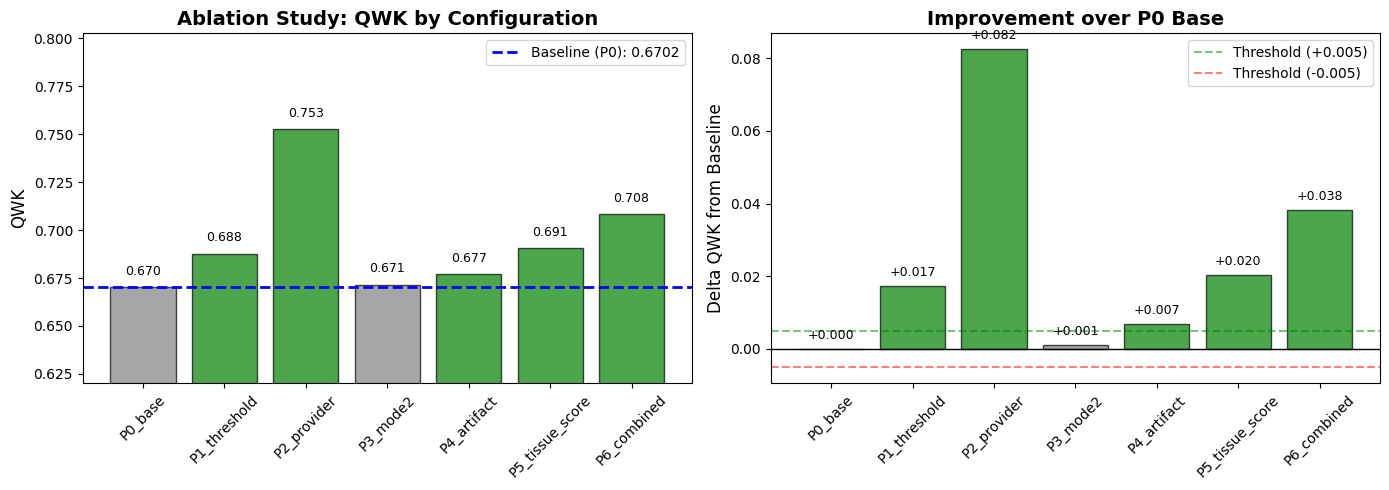

+ Saved to: /content/drive/MyDrive/CLAM_TR_Results/ablation_visualization.png

EXPERIMENT 2/4: UNI + CLAM

ABLATION STUDY
Encoder: uni, Model: clam

CONFIG: P0_base
Description: Base: tifffile + BGR->RGB + darkest selection
uni (Level 1 (P0_base)): Train=480, Val=120
  Model: CLAM, Parameters: 790,791
============================================================ Training: P0_base_uni_clam ============================================================
Already completed!

CONFIG: P1_threshold
Description: P0 + better threshold (0.90) + more tiles (500)
uni (Level 1 (P1_threshold)): Train=480, Val=120
  Model: CLAM, Parameters: 790,791
============================================================ Training: P1_threshold_uni_clam ============================================================
Already completed!

CONFIG: P2_provider
Description: P0 + provider-specific tile sizes
uni (Level 1 (P2_provider)): Train=480, Val=120
  Model: CLAM, Parameters: 790,791
======================================

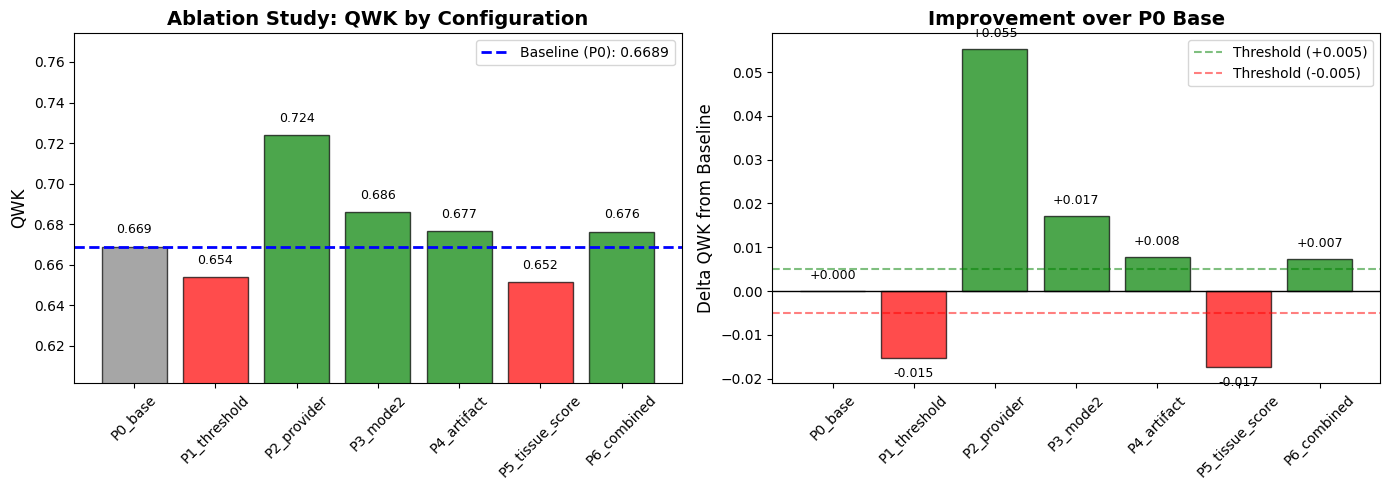

+ Saved to: /content/drive/MyDrive/CLAM_TR_Results/ablation_visualization.png

EXPERIMENT 3/4: ResNet50 + CLAM-TR

ABLATION STUDY
Encoder: resnet50, Model: clam_tr

CONFIG: P0_base
Description: Base: tifffile + BGR->RGB + darkest selection
  K=32 (avg patches: 44)
resnet50 (Level 1 (P0_base)): Train=480, Val=120
  Model: CLAM_TR, Parameters: 1,839,879
============================================================ Training: P0_base_resnet50_clam_tr_K32 ============================================================
Already completed!

CONFIG: P1_threshold
Description: P0 + better threshold (0.90) + more tiles (500)
  K=32 (avg patches: 35)
resnet50 (Level 1 (P1_threshold)): Train=480, Val=120
  Model: CLAM_TR, Parameters: 1,839,879
============================================================ Training: P1_threshold_resnet50_clam_tr_K32 ============================================================
Already completed!

CONFIG: P2_provider
Description: P0 + provider-specific tile sizes
  K=32 (avg

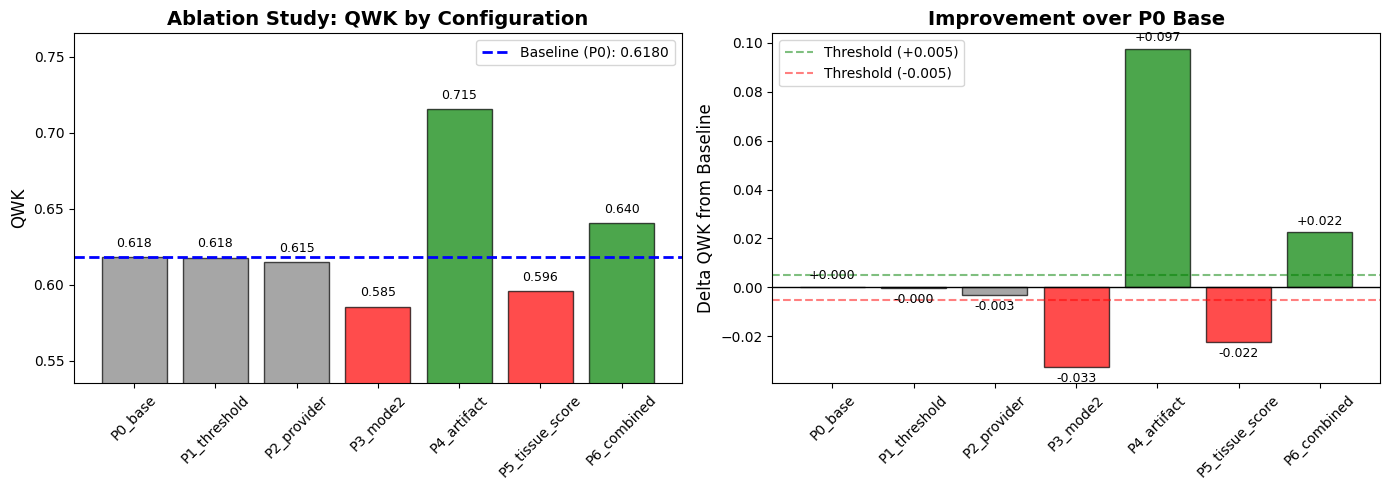

+ Saved to: /content/drive/MyDrive/CLAM_TR_Results/ablation_visualization.png

EXPERIMENT 4/4: ResNet50 + CLAM

ABLATION STUDY
Encoder: resnet50, Model: clam

CONFIG: P0_base
Description: Base: tifffile + BGR->RGB + darkest selection
resnet50 (Level 1 (P0_base)): Train=480, Val=120
  Model: CLAM, Parameters: 790,791
============================================================ Training: P0_base_resnet50_clam ============================================================
Already completed!

CONFIG: P1_threshold
Description: P0 + better threshold (0.90) + more tiles (500)
resnet50 (Level 1 (P1_threshold)): Train=480, Val=120
  Model: CLAM, Parameters: 790,791
============================================================ Training: P1_threshold_resnet50_clam ============================================================
Already completed!

CONFIG: P2_provider
Description: P0 + provider-specific tile sizes
resnet50 (Level 1 (P2_provider)): Train=480, Val=120
  Model: CLAM, Parameters: 790,791
===

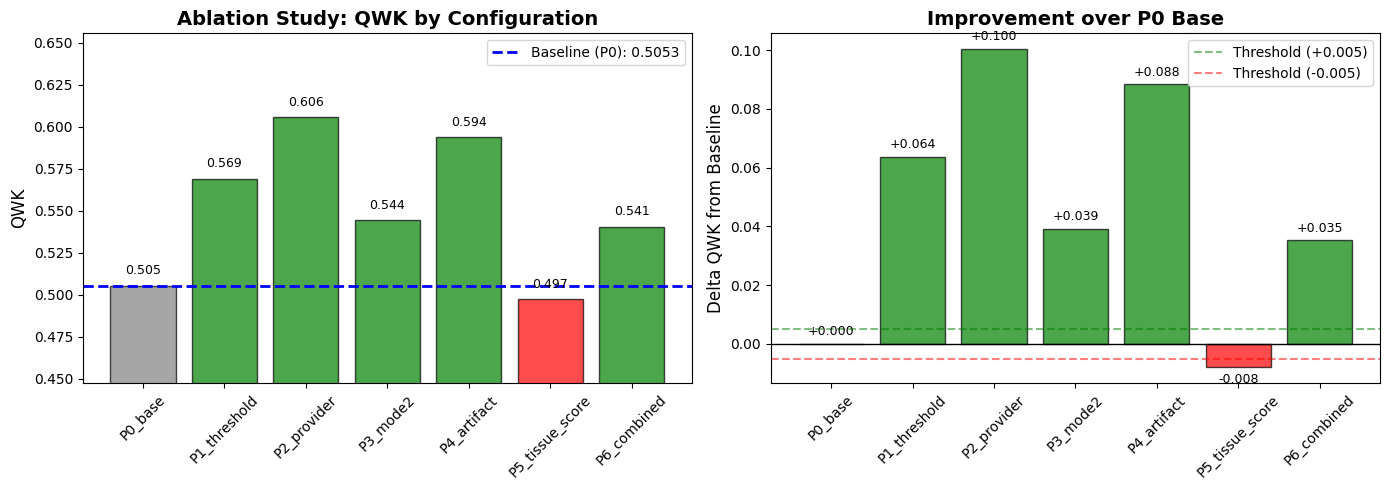

+ Saved to: /content/drive/MyDrive/CLAM_TR_Results/ablation_visualization.png

ABLATION STUDY COMPLETE - ALL COMBINATIONS

Experiment                Best Config       Best QWK
-------------------------------------------------------
uni_clam_tr               P2_provider         0.7527
uni_clam                  P2_provider         0.7241
resnet50_clam_tr          P4_artifact         0.7154
resnet50_clam             P2_provider         0.6057


In [23]:
# ============================================================
# ABLATION STUDY RUNNER
# ============================================================

def calculate_K_for_config(config_name, encoder_name):
    """
    Calculate optimal K value based on average patch count for config.
    K = number of top patches to select for spatial retention.
    """
    features_dir = get_features_dir(config_name, encoder_name)

    if not os.path.exists(features_dir):
        return CONFIG.get('default_K', 128)

    # Sample some slides to estimate average patch count
    feature_files = [f for f in os.listdir(features_dir) if f.endswith('.pt')][:50]

    if not feature_files:
        return CONFIG.get('default_K', 128)

    patch_counts = []
    for f in feature_files:
        try:
            data = torch.load(os.path.join(features_dir, f), map_location='cpu', weights_only=False)
            patch_counts.append(data['features'].shape[0])
        except:
            continue

    if not patch_counts:
        return CONFIG.get('default_K', 128)

    avg_patches = np.mean(patch_counts)

    # K should be roughly 25-50% of average patch count
    K = min(int(avg_patches * 0.4), 256)
    K = max(K, 32)  # At least 32

    print(f"  K={K} (avg patches: {avg_patches:.0f})")
    return K


def run_ablation_study(encoder_name='uni', model_type='clam_tr'):
    """
    Run complete ablation study for all 7 preprocessing configs.

    Args:
        encoder_name: 'uni' or 'resnet50'
        model_type: 'clam' or 'clam_tr'

    Returns:
        dict: Results for each config
    """
    print("\n" + "="*70)
    print("ABLATION STUDY")
    print(f"Encoder: {encoder_name}, Model: {model_type}")
    print("="*70)

    results = {}

    for config_name in ABLATION_CONFIGS.keys():
        print(f"\n{'='*60}")
        print(f"CONFIG: {config_name}")
        print(f"Description: {ABLATION_CONFIGS[config_name]['description']}")
        print(f"{'='*60}")

        # Check features exist
        features_dir = get_features_dir(config_name, encoder_name)
        if not os.path.exists(features_dir):
            print(f"! Skipping {config_name} - features not found")
            print(f"   Run: run_feature_extraction_config('{config_name}', '{encoder_name}')")
            continue

        feature_count = len([f for f in os.listdir(features_dir) if f.endswith('.pt')])
        if feature_count < 100:
            print(f"! Skipping {config_name} - insufficient features ({feature_count})")
            continue

        # Calculate K for CLAM-TR
        K = calculate_K_for_config(config_name, encoder_name) if model_type == 'clam_tr' else 0

        # Create dataloaders using updated function
        train_loader, val_loader, train_df, val_df = create_dataloaders(encoder_name, config_name)

        if train_loader is None:
            print(f"! Skipping {config_name} - could not prepare data")
            continue

        # Create model
        feature_dim = 1024  # Both UNI and ResNet50 output 1024-dim

        if model_type == 'clam_tr':
            model = CLAM_TR(
                input_dim=feature_dim,
                hidden_dim=CONFIG['hidden_dim'],
                n_classes=CONFIG['n_classes'],
                dropout=CONFIG['dropout'],
                K=K,
                num_heads=CONFIG['num_heads']
            )
        else:
            model = CLAM(
                input_dim=feature_dim,
                hidden_dim=CONFIG['hidden_dim'],
                n_classes=CONFIG['n_classes'],
                dropout=CONFIG['dropout']
            )

        print(f"  Model: {model_type.upper()}, Parameters: {count_parameters(model):,}")

        # Experiment name for checkpointing
        experiment_name = f"{config_name}_{encoder_name}_{model_type}"
        if model_type == 'clam_tr':
            experiment_name += f"_K{K}"

        # Train using updated run_training function
        metrics = run_training(
            model, train_loader, val_loader,
            experiment_name, model_type, config_name
        )

        if metrics:
            results[config_name] = {
                'qwk': metrics.get('qwk', 0),
                'accuracy': metrics.get('accuracy', 0),
                'macro_f1': metrics.get('macro_f1', 0),
                'K': K,
                'best_qwk': metrics.get('qwk', 0),
                **metrics
            }

        # Clear GPU memory
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Generate comparison
    if results:
        generate_ablation_comparison(results)
        plot_ablation_results(results)

    return results


def generate_ablation_comparison(results):
    """Generate comparison table and save results."""
    if not results:
        print("No results to compare!")
        return

    print("\n" + "="*70)
    print("ABLATION STUDY RESULTS")
    print("="*70)

    baseline_qwk = results.get('P0_base', {}).get('qwk', 0)

    print(f"\n{'Config':<20} {'QWK':>8} {'Delta':>10} {'Accuracy':>10} {'K':>6} {'Status':>8}")
    print("-"*70)

    for config_name in ABLATION_CONFIGS.keys():
        if config_name not in results:
            print(f"{config_name:<20} {'N/A':>8} {'N/A':>10} {'N/A':>10} {'N/A':>6} {'SKIP':>8}")
            continue

        metrics = results[config_name]
        qwk = metrics['qwk']
        acc = metrics['accuracy']
        K = metrics.get('K', 0)
        delta = qwk - baseline_qwk

        if delta > 0.005:
            status = "+ HELPS"
        elif delta < -0.005:
            status = "- HURTS"
        else:
            status = "= SAME"

        print(f"{config_name:<20} {qwk:>8.4f} {delta:>+10.4f} {acc:>10.4f} {K:>6} {status:>8}")

    # Save to CSV
    df = pd.DataFrame([
        {
            'config': k,
            'qwk': v['qwk'],
            'accuracy': v['accuracy'],
            'macro_f1': v.get('macro_f1', 0),
            'K': v.get('K', 0),
            'delta_qwk': v['qwk'] - baseline_qwk
        }
        for k, v in results.items()
    ])

    csv_path = os.path.join(CONFIG['results_dir'], 'ablation_results.csv')
    os.makedirs(os.path.dirname(csv_path), exist_ok=True)
    df.to_csv(csv_path, index=False)
    print(f"\n+ Results saved to: {csv_path}")

    # Recommendations
    print("\n" + "="*70)
    print("RECOMMENDATIONS")
    print("="*70)

    helpful = [k for k, v in results.items() if k != 'P0_base' and v['qwk'] - baseline_qwk > 0.005]
    harmful = [k for k, v in results.items() if v['qwk'] - baseline_qwk < -0.005]

    print(f"\n+ Techniques that HELP: {', '.join(helpful) if helpful else 'None'}")
    print(f"- Techniques that HURT: {', '.join(harmful) if harmful else 'None'}")

    if results:
        best_config = max(results.keys(), key=lambda k: results[k]['qwk'])
        print(f"\n*** BEST CONFIG: {best_config} (QWK: {results[best_config]['qwk']:.4f})")


def plot_ablation_results(results):
    """Visualize ablation study results."""
    if not results:
        print("No results to plot!")
        return

    configs = [c for c in ABLATION_CONFIGS.keys() if c in results]
    qwks = [results[c]['qwk'] for c in configs]
    baseline = results.get('P0_base', {}).get('qwk', qwks[0] if qwks else 0)
    deltas = [q - baseline for q in qwks]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot 1: QWK by config
    colors = ['green' if d > 0.005 else 'red' if d < -0.005 else 'gray' for d in deltas]
    bars1 = axes[0].bar(configs, qwks, color=colors, alpha=0.7, edgecolor='black')
    axes[0].axhline(y=baseline, color='blue', linestyle='--', linewidth=2,
                    label=f'Baseline (P0): {baseline:.4f}')
    axes[0].set_ylabel('QWK', fontsize=12)
    axes[0].set_title('Ablation Study: QWK by Configuration', fontsize=14, fontweight='bold')
    axes[0].tick_params(axis='x', rotation=45)
    axes[0].legend()
    axes[0].set_ylim(min(qwks) - 0.05, max(qwks) + 0.05)

    for bar, qwk in zip(bars1, qwks):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                     f'{qwk:.3f}', ha='center', va='bottom', fontsize=9)

    # Plot 2: Delta from baseline
    bars2 = axes[1].bar(configs, deltas, color=colors, alpha=0.7, edgecolor='black')
    axes[1].axhline(y=0, color='black', linestyle='-', linewidth=1)
    axes[1].axhline(y=0.005, color='green', linestyle='--', alpha=0.5, label='Threshold (+0.005)')
    axes[1].axhline(y=-0.005, color='red', linestyle='--', alpha=0.5, label='Threshold (-0.005)')
    axes[1].set_ylabel('Delta QWK from Baseline', fontsize=12)
    axes[1].set_title('Improvement over P0 Base', fontsize=14, fontweight='bold')
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].legend()

    for bar, delta in zip(bars2, deltas):
        va = 'bottom' if delta >= 0 else 'top'
        offset = 0.002 if delta >= 0 else -0.002
        axes[1].text(bar.get_x() + bar.get_width()/2, delta + offset,
                     f'{delta:+.3f}', ha='center', va=va, fontsize=9)

    plt.tight_layout()

    save_path = os.path.join(CONFIG['results_dir'], 'ablation_visualization.png')
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"+ Saved to: {save_path}")

print("Ablation study functions defined!")
print("  - calculate_K_for_config(config_name, encoder_name)")
print("  - run_ablation_study(encoder_name, model_type)")
print("  - generate_ablation_comparison(results)")
print("  - plot_ablation_results(results)")

# ============================================================
# RUN ABLATION STUDY - SINGLE EXPERIMENT
# ============================================================
# results = run_ablation_study(encoder_name='uni', model_type='clam_tr')

# ============================================================
# RUN COMPLETE ABLATION STUDY (ALL 4 COMBINATIONS)
# ============================================================
# Encoder options: uni, resnet50
# Model options: clam, clam_tr
# Total: 4 experiments x 7 configs = 28 training runs
# ============================================================

all_results = {}

# 1. UNI + CLAM-TR
print('\n' + '='*70)
print('EXPERIMENT 1/4: UNI + CLAM-TR')
print('='*70)
all_results['uni_clam_tr'] = run_ablation_study(encoder_name='uni', model_type='clam_tr')

# 2. UNI + CLAM
print('\n' + '='*70)
print('EXPERIMENT 2/4: UNI + CLAM')
print('='*70)
all_results['uni_clam'] = run_ablation_study(encoder_name='uni', model_type='clam')

# 3. ResNet50 + CLAM-TR
print('\n' + '='*70)
print('EXPERIMENT 3/4: ResNet50 + CLAM-TR')
print('='*70)
all_results['resnet50_clam_tr'] = run_ablation_study(encoder_name='resnet50', model_type='clam_tr')

# 4. ResNet50 + CLAM
print('\n' + '='*70)
print('EXPERIMENT 4/4: ResNet50 + CLAM')
print('='*70)
all_results['resnet50_clam'] = run_ablation_study(encoder_name='resnet50', model_type='clam')

# Print summary
print('\n' + '='*70)
print('ABLATION STUDY COMPLETE - ALL COMBINATIONS')
print('='*70)
print(f"\n{'Experiment':<25} {'Best Config':<15} {'Best QWK':>10}")
print('-'*55)
for exp_name, results in all_results.items():
    if results:
        best_config = max(results.keys(), key=lambda k: results[k].get('qwk', 0))
        best_qwk = results[best_config].get('qwk', 0)
        print(f'{exp_name:<25} {best_config:<15} {best_qwk:>10.4f}')


# Section 13: K Ablation Study (K = 32, 64, 128, 256, 512)

K Ablation Study functions defined!
  - run_k_ablation_study(encoder_name, config_name)
  - plot_k_ablation_results(k_ablation_results)

K ABLATION STUDY
Encoder: uni, Config: P0_base
K values: [32, 64, 128, 256, 512]
Features found: 600

K = 32
uni (Level 1 (P0_base)): Train=480, Val=120
Model parameters: 1,839,879
============================================================ Training: k_ablation_P0_base_uni_K32 ============================================================
Already completed!

K = 64
uni (Level 1 (P0_base)): Train=480, Val=120
Model parameters: 1,839,879
============================================================ Training: k_ablation_P0_base_uni_K64 ============================================================
Already completed!

K = 128
uni (Level 1 (P0_base)): Train=480, Val=120
Model parameters: 1,839,879
============================================================ Training: k_ablation_P0_base_uni_K128 ============================================================
Alrea

Train:   0%|          | 0/480 [00:00<?, ?it/s]

Val:   0%|          | 0/120 [00:00<?, ?it/s]

Epoch 41: Train Loss=0.4992, Val QWK=0.6833, Val Acc=0.4583


Train:   0%|          | 0/480 [00:00<?, ?it/s]

Val:   0%|          | 0/120 [00:00<?, ?it/s]

... (23 outputs left out)

Val:   0%|          | 0/120 [00:00<?, ?it/s]

Epoch 50: Train Loss=0.4968, Val QWK=0.6769, Val Acc=0.4500


Val:   0%|          | 0/120 [00:00<?, ?it/s]

Final QWK: 0.7115, Acc: 0.4333

                       K ABLATION STUDY RESULTS                       
K                   QWK     Accuracy     Macro F1          AUC
----------------------------------------------------------
32               0.6550       0.4083       0.3710       0.7902
64               0.6968       0.4583       0.4196       0.8030
128              0.7091       0.4667       0.4626       0.7624
256              0.6853       0.4417       0.4348       0.7653
512              0.7115       0.4333       0.4190       0.7310

Best K = 512 with QWK = 0.7115

Results saved to: /content/drive/MyDrive/CLAM_TR_Results/k_ablation_P0_base_uni.csv


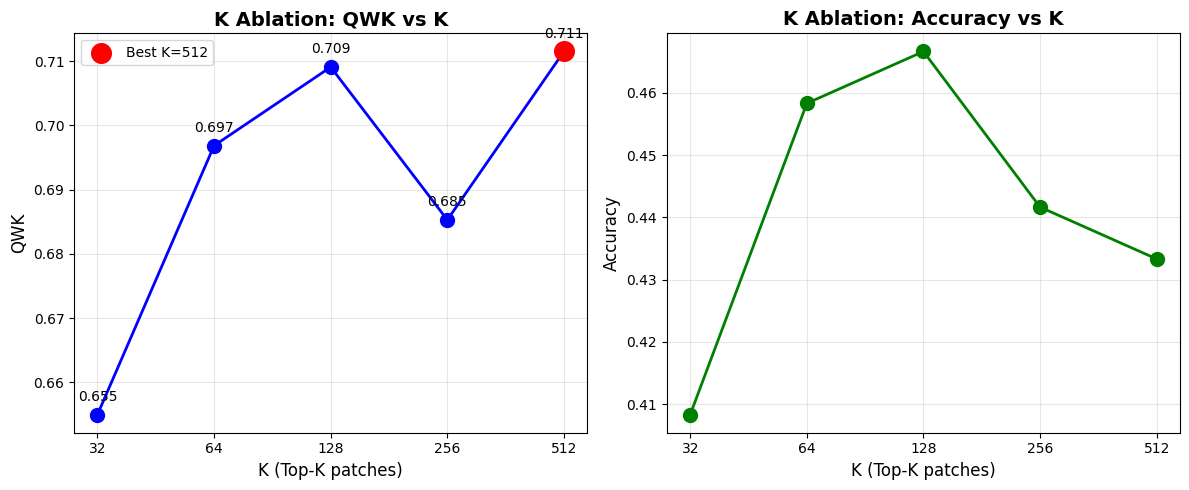

+ Saved to: /content/drive/MyDrive/CLAM_TR_Results/k_ablation_visualization.png


In [24]:
# ============================================================
# K ABLATION STUDY
# ============================================================
# Test different K values (Top-K selection for spatial retention)
# K determines how many top-attended patches are used in CLAM-TR
# ============================================================

def run_k_ablation_study(encoder_name='uni', config_name='P0_base'):
    """
    Run ablation study varying K values for CLAM-TR.

    Args:
        encoder_name: 'uni' or 'resnet50'
        config_name: Which preprocessing config to use

    Returns:
        dict: Results for each K value
    """
    K_values = [32, 64, 128, 256, 512]  # Different K values to test
    k_ablation_results = {}

    print('\n' + '='*70)
    print('K ABLATION STUDY')
    print(f'Encoder: {encoder_name}, Config: {config_name}')
    print(f'K values: {K_values}')
    print('='*70)

    # Check features exist
    features_dir = get_features_dir(config_name, encoder_name)
    if not os.path.exists(features_dir):
        print(f'ERROR: Features not found at {features_dir}')
        print(f'Run: run_feature_extraction_config("{config_name}", "{encoder_name}")')
        return k_ablation_results

    feature_count = len([f for f in os.listdir(features_dir) if f.endswith('.pt')])
    print(f'Features found: {feature_count}')

    if feature_count < 100:
        print('ERROR: Insufficient features for training')
        return k_ablation_results

    for K in K_values:
        print(f'\n{"="*60}')
        print(f'K = {K}')
        print(f'{"="*60}')

        exp_name = f'k_ablation_{config_name}_{encoder_name}_K{K}'

        # Prepare data using updated create_dataloaders
        train_loader, val_loader, train_df, val_df = create_dataloaders(encoder_name, config_name)

        if train_loader is None:
            print(f'! Skipping K={K} - could not prepare data')
            continue

        # Create CLAM-TR model with specific K
        feature_dim = 1024
        model = CLAM_TR(
            input_dim=feature_dim,
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            dropout=CONFIG['dropout'],
            K=K,
            num_heads=CONFIG['num_heads']
        )

        print(f'Model parameters: {count_parameters(model):,}')

        # Train using updated run_training
        try:
            metrics = run_training(
                model, train_loader, val_loader,
                exp_name, 'clam_tr', config_name
            )
            if metrics:
                k_ablation_results[K] = {
                    'best_qwk': metrics.get('qwk', 0),
                    'accuracy': metrics.get('accuracy', 0),
                    'macro_f1': metrics.get('macro_f1', 0),
                    'auc': metrics.get('auc', 0),
                    **metrics
                }
        except Exception as e:
            print(f'ERROR training K={K}: {e}')
            import traceback
            traceback.print_exc()

        # Cleanup
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Print summary
    if k_ablation_results:
        print(f'\n{"="*70}')
        print(f'{"K ABLATION STUDY RESULTS":^70}')
        print(f'{"="*70}')
        print(f'{"K":<10} {"QWK":>12} {"Accuracy":>12} {"Macro F1":>12} {"AUC":>12}')
        print(f'{"-"*58}')
        for K in sorted(k_ablation_results.keys()):
            m = k_ablation_results[K]
            print(f'{K:<10} {m.get("best_qwk", 0):>12.4f} {m.get("accuracy", 0):>12.4f} {m.get("macro_f1", 0):>12.4f} {m.get("auc", 0):>12.4f}')
        print(f'{"="*70}')

        # Best K
        best_K = max(k_ablation_results.keys(), key=lambda k: k_ablation_results[k].get('best_qwk', 0))
        print(f'\nBest K = {best_K} with QWK = {k_ablation_results[best_K].get("best_qwk", 0):.4f}')

        # Save results
        results_df = pd.DataFrame([
            {'K': K, 'QWK': m.get('best_qwk', 0), 'Accuracy': m.get('accuracy', 0),
             'Macro_F1': m.get('macro_f1', 0), 'AUC': m.get('auc', 0)}
            for K, m in k_ablation_results.items()
        ])
        results_path = os.path.join(CONFIG['results_dir'], f'k_ablation_{config_name}_{encoder_name}.csv')
        os.makedirs(os.path.dirname(results_path), exist_ok=True)
        results_df.to_csv(results_path, index=False)
        print(f'\nResults saved to: {results_path}')

    return k_ablation_results


def plot_k_ablation_results(k_ablation_results):
    """Visualize K ablation study results."""
    if not k_ablation_results:
        print("No K ablation results to plot!")
        return

    K_values = sorted(k_ablation_results.keys())
    qwks = [k_ablation_results[k].get('best_qwk', 0) for k in K_values]
    accs = [k_ablation_results[k].get('accuracy', 0) for k in K_values]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Plot 1: QWK vs K
    axes[0].plot(K_values, qwks, 'bo-', linewidth=2, markersize=10)
    axes[0].set_xlabel('K (Top-K patches)', fontsize=12)
    axes[0].set_ylabel('QWK', fontsize=12)
    axes[0].set_title('K Ablation: QWK vs K', fontsize=14, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    axes[0].set_xscale('log', base=2)
    axes[0].set_xticks(K_values)
    axes[0].set_xticklabels([str(k) for k in K_values])

    # Highlight best K
    best_idx = qwks.index(max(qwks))
    axes[0].scatter([K_values[best_idx]], [qwks[best_idx]], color='red', s=200, zorder=5, label=f'Best K={K_values[best_idx]}')
    axes[0].legend()

    # Add value labels
    for k, qwk in zip(K_values, qwks):
        axes[0].annotate(f'{qwk:.3f}', (k, qwk), textcoords="offset points", xytext=(0, 10), ha='center')

    # Plot 2: Accuracy vs K
    axes[1].plot(K_values, accs, 'go-', linewidth=2, markersize=10)
    axes[1].set_xlabel('K (Top-K patches)', fontsize=12)
    axes[1].set_ylabel('Accuracy', fontsize=12)
    axes[1].set_title('K Ablation: Accuracy vs K', fontsize=14, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    axes[1].set_xscale('log', base=2)
    axes[1].set_xticks(K_values)
    axes[1].set_xticklabels([str(k) for k in K_values])

    plt.tight_layout()

    save_path = os.path.join(CONFIG['results_dir'], 'k_ablation_visualization.png')
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f'+ Saved to: {save_path}')

print("K Ablation Study functions defined!")
print("  - run_k_ablation_study(encoder_name, config_name)")
print("  - plot_k_ablation_results(k_ablation_results)")

# ============================================================
# RUN K ABLATION STUDY
# ============================================================
# Test with best preprocessing config and encoder
k_ablation_results = run_k_ablation_study(encoder_name='uni', config_name='P0_base')

# Plot results
plot_k_ablation_results(k_ablation_results)


---
## Section 14: Visualizations

In [25]:
# ============================================================
# VISUALIZATION FUNCTIONS
# ============================================================

def plot_all_ablation_results(all_results):
    """
    Generate comprehensive visualization of ablation study results.

    Args:
        all_results: dict with keys like 'uni_clam_tr', 'uni_clam', etc.
                     Each value is a dict {config_name: metrics}
    """
    if not all_results:
        print("No results to visualize!")
        return

    fig = plt.figure(figsize=(20, 12))

    # --------------------------------------------------------
    # Plot 1: Best QWK per Encoder+Model Combination
    # --------------------------------------------------------
    ax1 = fig.add_subplot(2, 2, 1)

    exp_names = []
    best_qwks = []
    best_configs = []
    colors = ['#2ecc71', '#3498db', '#e74c3c', '#9b59b6']

    for i, (exp_name, results) in enumerate(all_results.items()):
        if results:
            best_config = max(results.keys(), key=lambda k: results[k].get('qwk', 0))
            best_qwk = results[best_config].get('qwk', 0)
            exp_names.append(exp_name.replace('_', '\n'))
            best_qwks.append(best_qwk)
            best_configs.append(best_config)

    if exp_names:
        bars = ax1.bar(range(len(exp_names)), best_qwks, color=colors[:len(exp_names)], edgecolor='black')
        ax1.set_xticks(range(len(exp_names)))
        ax1.set_xticklabels(exp_names, fontsize=10)
        ax1.set_ylabel('Best QWK', fontsize=12)
        ax1.set_title('Best QWK per Encoder+Model Combination', fontsize=14, fontweight='bold')
        ax1.set_ylim(0, 1.0)

        # Add value and config labels
        for bar, qwk, config in zip(bars, best_qwks, best_configs):
            ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                    f'{qwk:.3f}\n({config})', ha='center', fontsize=9, fontweight='bold')

    # --------------------------------------------------------
    # Plot 2: QWK by Preprocessing Config (for best combo)
    # --------------------------------------------------------
    ax2 = fig.add_subplot(2, 2, 2)

    # Use uni_clam_tr as primary comparison
    primary_exp = 'uni_clam_tr'
    if primary_exp in all_results and all_results[primary_exp]:
        results = all_results[primary_exp]
        configs = list(results.keys())
        qwks = [results[c].get('qwk', 0) for c in configs]

        baseline_qwk = results.get('P0_base', {}).get('qwk', qwks[0] if qwks else 0)
        colors = ['green' if q > baseline_qwk + 0.005 else 'red' if q < baseline_qwk - 0.005 else 'gray' for q in qwks]

        bars = ax2.bar(range(len(configs)), qwks, color=colors, edgecolor='black', alpha=0.7)
        ax2.axhline(y=baseline_qwk, color='blue', linestyle='--', linewidth=2, label=f'Baseline (P0): {baseline_qwk:.3f}')
        ax2.set_xticks(range(len(configs)))
        ax2.set_xticklabels(configs, fontsize=9, rotation=45, ha='right')
        ax2.set_ylabel('QWK', fontsize=12)
        ax2.set_title(f'Preprocessing Ablation ({primary_exp})', fontsize=14, fontweight='bold')
        ax2.legend()

        for bar, qwk in zip(bars, qwks):
            ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                    f'{qwk:.3f}', ha='center', fontsize=8)

    # --------------------------------------------------------
    # Plot 3: CLAM vs CLAM-TR Comparison
    # --------------------------------------------------------
    ax3 = fig.add_subplot(2, 2, 3)

    # Compare CLAM vs CLAM-TR for each encoder
    encoders = ['uni', 'resnet50']
    x = np.arange(len(encoders))
    width = 0.35

    clam_qwks = []
    clamtr_qwks = []

    for encoder in encoders:
        clam_key = f'{encoder}_clam'
        clamtr_key = f'{encoder}_clam_tr'

        # Get best QWK for each
        if clam_key in all_results and all_results[clam_key]:
            best = max(all_results[clam_key].values(), key=lambda v: v.get('qwk', 0))
            clam_qwks.append(best.get('qwk', 0))
        else:
            clam_qwks.append(0)

        if clamtr_key in all_results and all_results[clamtr_key]:
            best = max(all_results[clamtr_key].values(), key=lambda v: v.get('qwk', 0))
            clamtr_qwks.append(best.get('qwk', 0))
        else:
            clamtr_qwks.append(0)

    bars1 = ax3.bar(x - width/2, clam_qwks, width, label='CLAM', color='#3498db', alpha=0.8)
    bars2 = ax3.bar(x + width/2, clamtr_qwks, width, label='CLAM-TR', color='#2ecc71', alpha=0.8)

    ax3.set_xticks(x)
    ax3.set_xticklabels(['UNI', 'ResNet50'], fontsize=12)
    ax3.set_ylabel('Best QWK', fontsize=12)
    ax3.set_title('CLAM vs CLAM-TR by Encoder', fontsize=14, fontweight='bold')
    ax3.set_ylim(0, 1.0)
    ax3.legend()

    # Add improvement labels
    for i, (c, ct) in enumerate(zip(clam_qwks, clamtr_qwks)):
        if c > 0 and ct > 0:
            imp = (ct - c) / c * 100
            color = 'green' if imp > 0 else 'red'
            ax3.annotate(f'{imp:+.1f}%', xy=(i + 0.15, max(c, ct) + 0.02),
                        ha='center', fontsize=10, color=color, fontweight='bold')

    # --------------------------------------------------------
    # Plot 4: Summary
    # --------------------------------------------------------
    ax4 = fig.add_subplot(2, 2, 4)
    ax4.axis('off')

    summary_text = "ABLATION STUDY SUMMARY\n" + "="*45 + "\n\n"

    # Find overall best
    overall_best_qwk = 0
    overall_best_exp = ""
    overall_best_config = ""

    for exp_name, results in all_results.items():
        if results:
            for config_name, metrics in results.items():
                qwk = metrics.get('qwk', 0)
                if qwk > overall_best_qwk:
                    overall_best_qwk = qwk
                    overall_best_exp = exp_name
                    overall_best_config = config_name

    summary_text += f"BEST OVERALL:\n"
    summary_text += f"  Experiment: {overall_best_exp}\n"
    summary_text += f"  Config:     {overall_best_config}\n"
    summary_text += f"  QWK:        {overall_best_qwk:.4f}\n\n"

    # Best per experiment
    summary_text += f"BEST PER EXPERIMENT:\n"
    for exp_name, results in all_results.items():
        if results:
            best_config = max(results.keys(), key=lambda k: results[k].get('qwk', 0))
            best_qwk = results[best_config].get('qwk', 0)
            summary_text += f"  {exp_name}: {best_qwk:.4f} ({best_config})\n"

    summary_text += f"\n" + "="*45

    ax4.text(0.05, 0.95, summary_text, transform=ax4.transAxes,
             fontsize=11, verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.tight_layout()

    # Save
    save_path = os.path.join(CONFIG['results_dir'], 'ablation_complete_results.png')
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"\n+ Saved: {save_path}")


def plot_config_comparison(all_results, config_name='P0_base'):
    """
    Compare all encoder+model combinations for a specific config.

    Args:
        all_results: dict from run_ablation_study
        config_name: Which config to compare
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    exp_names = []
    qwks = []
    colors = ['#2ecc71', '#3498db', '#e74c3c', '#9b59b6']

    for exp_name, results in all_results.items():
        if results and config_name in results:
            exp_names.append(exp_name.replace('_', '\n'))
            qwks.append(results[config_name].get('qwk', 0))

    if not exp_names:
        print(f"No results found for config: {config_name}")
        return

    bars = ax.bar(range(len(exp_names)), qwks, color=colors[:len(exp_names)], edgecolor='black')
    ax.set_xticks(range(len(exp_names)))
    ax.set_xticklabels(exp_names, fontsize=11)
    ax.set_ylabel('QWK', fontsize=12)
    ax.set_title(f'Encoder+Model Comparison for {config_name}', fontsize=14, fontweight='bold')
    ax.set_ylim(0, 1.0)

    for bar, qwk in zip(bars, qwks):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{qwk:.3f}', ha='center', fontsize=11, fontweight='bold')

    plt.tight_layout()

    save_path = os.path.join(CONFIG['results_dir'], f'comparison_{config_name}.png')
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"+ Saved: {save_path}")


def plot_encoder_comparison(all_results):
    """Compare UNI vs ResNet50 encoders."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Get all configs
    configs = list(ABLATION_CONFIGS.keys())

    # CLAM-TR comparison
    ax1 = axes[0]
    uni_qwks = []
    resnet_qwks = []

    for config in configs:
        if 'uni_clam_tr' in all_results and config in all_results['uni_clam_tr']:
            uni_qwks.append(all_results['uni_clam_tr'][config].get('qwk', 0))
        else:
            uni_qwks.append(0)

        if 'resnet50_clam_tr' in all_results and config in all_results['resnet50_clam_tr']:
            resnet_qwks.append(all_results['resnet50_clam_tr'][config].get('qwk', 0))
        else:
            resnet_qwks.append(0)

    x = np.arange(len(configs))
    width = 0.35

    ax1.bar(x - width/2, uni_qwks, width, label='UNI', color='#2ecc71', alpha=0.8)
    ax1.bar(x + width/2, resnet_qwks, width, label='ResNet50', color='#3498db', alpha=0.8)
    ax1.set_xticks(x)
    ax1.set_xticklabels(configs, fontsize=9, rotation=45, ha='right')
    ax1.set_ylabel('QWK', fontsize=12)
    ax1.set_title('UNI vs ResNet50 (CLAM-TR)', fontsize=14, fontweight='bold')
    ax1.legend()

    # CLAM comparison
    ax2 = axes[1]
    uni_qwks = []
    resnet_qwks = []

    for config in configs:
        if 'uni_clam' in all_results and config in all_results['uni_clam']:
            uni_qwks.append(all_results['uni_clam'][config].get('qwk', 0))
        else:
            uni_qwks.append(0)

        if 'resnet50_clam' in all_results and config in all_results['resnet50_clam']:
            resnet_qwks.append(all_results['resnet50_clam'][config].get('qwk', 0))
        else:
            resnet_qwks.append(0)

    ax2.bar(x - width/2, uni_qwks, width, label='UNI', color='#2ecc71', alpha=0.8)
    ax2.bar(x + width/2, resnet_qwks, width, label='ResNet50', color='#3498db', alpha=0.8)
    ax2.set_xticks(x)
    ax2.set_xticklabels(configs, fontsize=9, rotation=45, ha='right')
    ax2.set_ylabel('QWK', fontsize=12)
    ax2.set_title('UNI vs ResNet50 (CLAM)', fontsize=14, fontweight='bold')
    ax2.legend()

    plt.tight_layout()

    save_path = os.path.join(CONFIG['results_dir'], 'encoder_comparison.png')
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"+ Saved: {save_path}")

print("Visualization functions defined!")
print("  - plot_all_ablation_results(all_results)")
print("  - plot_config_comparison(all_results, config_name)")
print("  - plot_encoder_comparison(all_results)")

# ============================================================
# GENERATE VISUALIZATIONS
# ============================================================
# plot_all_ablation_results(all_results)
# plot_config_comparison(all_results, 'P0_base')
# plot_encoder_comparison(all_results)


Visualization functions defined!
  - plot_all_ablation_results(all_results)
  - plot_config_comparison(all_results, config_name)
  - plot_encoder_comparison(all_results)


# Section 15: Advanced Visualizations (Attention Analysis)

In [26]:
# ============================================================================
# ADVANCED VISUALIZATION 1: Top-K Patches Grid
# ============================================================================

def load_model_for_visualization(config_name, encoder_name, model_type='clam_tr'):
    """
    Load trained model for visualization.

    Args:
        config_name: Preprocessing config name
        encoder_name: 'uni' or 'resnet50'
        model_type: 'clam' or 'clam_tr'

    Returns:
        model: Loaded model, or None if not found
    """
    results_dir = get_results_dir(config_name)

    # Find the model file
    models_dir = os.path.join(results_dir, 'models')
    if not os.path.exists(models_dir):
        print(f"Models directory not found: {models_dir}")
        return None

    # Look for matching model file
    pattern = f"{config_name}_{encoder_name}_{model_type}"
    model_files = [f for f in os.listdir(models_dir) if pattern in f and f.endswith('.pt')]

    if not model_files:
        print(f"No model found matching: {pattern}")
        return None

    model_path = os.path.join(models_dir, model_files[0])
    print(f"Loading model: {model_path}")

    # Create model
    feature_dim = 1024
    if model_type == 'clam_tr':
        model = CLAM_TR(
            input_dim=feature_dim,
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            dropout=CONFIG['dropout'],
            K=CONFIG.get('default_K', 128),
            num_heads=CONFIG['num_heads']
        )
    else:
        model = CLAM(
            input_dim=feature_dim,
            hidden_dim=CONFIG['hidden_dim'],
            n_classes=CONFIG['n_classes'],
            dropout=CONFIG['dropout']
        )

    # Load weights
    model.load_state_dict(torch.load(model_path, map_location=DEVICE, weights_only=False))
    model = model.to(DEVICE)
    model.eval()

    return model


def load_slide_features(slide_id, config_name, encoder_name):
    """
    Load features for a specific slide.

    Returns:
        features: Tensor [N, D]
        coords: Tensor [N, 2]
    """
    features_dir = get_features_dir(config_name, encoder_name)
    feature_path = os.path.join(features_dir, f"{slide_id}.pt")

    if not os.path.exists(feature_path):
        print(f"Features not found: {feature_path}")
        return None, None

    data = torch.load(feature_path, map_location='cpu', weights_only=False)
    return data['features'], data['coordinates']


def visualize_topk_patches(model, features, coords, slide_id, config_name, top_n=16):
    """
    Display the top-N most attended patches from CLAM-TR.

    Args:
        model: Trained CLAM-TR model
        features: Tensor of patch features [N, D]
        coords: Tensor of patch coordinates [N, 2]
        slide_id: Slide identifier
        config_name: Preprocessing config (to find patches directory)
        top_n: Number of top patches to display

    Returns:
        dict: Information about top-K patches
    """
    model.eval()

    with torch.no_grad():
        features = features.to(DEVICE)
        coords_device = coords.to(DEVICE)

        # Get attention scores - handle both CLAM and CLAM-TR
        result = model(features, coords_device, return_attention=True)

        # CLAM-TR returns (logits, attention, topk_indices)
        # CLAM returns (logits, attention)
        if len(result) == 3:
            logits, attention, topk_indices = result
        else:
            logits, attention = result
            topk_indices = None

        attention = attention.cpu().numpy().flatten()
        coords_np = coords.cpu().numpy()

    # Get top-N indices by attention
    top_indices = np.argsort(attention)[-top_n:][::-1]

    # Get patches directory
    config = ABLATION_CONFIGS[config_name]
    patches_dir = os.path.join(CONFIG['preprocessing_dir'], config['patches_folder'])
    slide_patches_dir = os.path.join(patches_dir, slide_id)

    if not os.path.exists(slide_patches_dir):
        print(f'Patches not found for {slide_id} at {slide_patches_dir}')
        return None

    # Create grid
    n_cols = 4
    n_rows = (top_n + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4*n_rows))
    axes = axes.flatten()

    for i, idx in enumerate(top_indices):
        x, y = coords_np[idx]
        patch_path = os.path.join(slide_patches_dir, f'patch_{int(x)}_{int(y)}.png')

        if os.path.exists(patch_path):
            patch = Image.open(patch_path)
            axes[i].imshow(patch)
            axes[i].set_title(f'Rank {i+1}\nAttn: {attention[idx]:.4f}\nCoord: ({int(x)}, {int(y)})', fontsize=10)
        else:
            axes[i].text(0.5, 0.5, 'Not found', ha='center', va='center', transform=axes[i].transAxes)
            axes[i].set_title(f'Rank {i+1} - Missing')

        axes[i].axis('off')

    # Hide unused axes
    for i in range(top_n, len(axes)):
        axes[i].axis('off')

    plt.suptitle(f'Top-{top_n} Attended Patches - {slide_id} ({config_name})', fontsize=14)
    plt.tight_layout()

    # Save
    save_path = os.path.join(CONFIG['results_dir'], 'visualizations', f'topk_patches_{config_name}_{slide_id}.png')
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

    print(f"+ Saved: {save_path}")

    return {
        'slide_id': slide_id,
        'config_name': config_name,
        'top_indices': top_indices.tolist(),
        'top_attention': attention[top_indices].tolist(),
        'top_coords': coords_np[top_indices].tolist()
    }


def visualize_topk_for_slide(slide_id, config_name='P0_base', encoder_name='uni', model_type='clam_tr', top_n=16):
    """
    Convenience function to visualize top-K patches for a slide.
    Loads model and features automatically.
    """
    # Load model
    model = load_model_for_visualization(config_name, encoder_name, model_type)
    if model is None:
        return None

    # Load features
    features, coords = load_slide_features(slide_id, config_name, encoder_name)
    if features is None:
        return None

    # Visualize
    return visualize_topk_patches(model, features, coords, slide_id, config_name, top_n)

print('Advanced Visualization 1: Top-K Patches Grid - DEFINED')
print('  - load_model_for_visualization(config_name, encoder_name, model_type)')
print('  - load_slide_features(slide_id, config_name, encoder_name)')
print('  - visualize_topk_patches(model, features, coords, slide_id, config_name, top_n)')
print('  - visualize_topk_for_slide(slide_id, config_name, encoder_name, model_type, top_n)')


Advanced Visualization 1: Top-K Patches Grid - DEFINED
  - load_model_for_visualization(config_name, encoder_name, model_type)
  - load_slide_features(slide_id, config_name, encoder_name)
  - visualize_topk_patches(model, features, coords, slide_id, config_name, top_n)
  - visualize_topk_for_slide(slide_id, config_name, encoder_name, model_type, top_n)


In [27]:
# ============================================================================
# ADVANCED VISUALIZATION 2: Spatial Retention Graph
# ============================================================================

def visualize_spatial_retention(model, features, coords, slide_id, config_name, gamma=0.95, top_connections=50):
    """
    Visualize spatial retention connections between Top-K patches.

    This shows how CLAM-TR models spatial relationships using retention mechanism.

    Args:
        model: Trained CLAM-TR model
        features: Tensor of patch features [N, D]
        coords: Tensor of patch coordinates [N, 2]
        slide_id: Slide identifier
        config_name: Preprocessing config name
        gamma: Decay factor for retention
        top_connections: Number of top connections to show

    Returns:
        dict: Statistics about spatial retention
    """
    model.eval()

    with torch.no_grad():
        features = features.to(DEVICE)
        coords_tensor = coords.to(DEVICE)

        # Get attention and top-K
        h = model.feature_transform(features)
        A = model.attention(h)
        A_softmax = F.softmax(A, dim=0)

        K_actual = min(model.K, h.size(0))
        topk_indices = torch.topk(A.squeeze(), K_actual).indices

        coords_topk = coords_tensor[topk_indices].cpu().numpy()
        attn_topk = A_softmax[topk_indices].cpu().numpy().flatten()

    # Calculate pairwise distances
    n_patches = len(coords_topk)
    distances = np.zeros((n_patches, n_patches))
    for i in range(n_patches):
        for j in range(n_patches):
            distances[i, j] = np.sqrt(np.sum((coords_topk[i] - coords_topk[j])**2))

    # Calculate retention weights (gamma^distance)
    max_dist = distances.max() if distances.max() > 0 else 1
    normalized_dist = distances / max_dist
    retention_weights = gamma ** (normalized_dist * 10)  # Scale factor

    # Create visualization
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # Panel 1: Patch locations with attention
    ax = axes[0]
    scatter = ax.scatter(coords_topk[:, 0], coords_topk[:, 1],
                         c=attn_topk, cmap='hot', s=100, alpha=0.8)
    plt.colorbar(scatter, ax=ax, label='Attention')
    ax.set_title(f'Top-K Patch Locations\n(K={K_actual})', fontsize=12)
    ax.set_xlabel('X coordinate')
    ax.set_ylabel('Y coordinate')
    ax.invert_yaxis()

    # Panel 2: Spatial connections graph
    ax = axes[1]
    ax.scatter(coords_topk[:, 0], coords_topk[:, 1], c='blue', s=50, zorder=5)

    # Draw top connections
    connections = []
    for i in range(n_patches):
        for j in range(i+1, n_patches):
            connections.append((i, j, retention_weights[i, j]))

    connections.sort(key=lambda x: x[2], reverse=True)

    for i, j, weight in connections[:top_connections]:
        ax.plot([coords_topk[i, 0], coords_topk[j, 0]],
                [coords_topk[i, 1], coords_topk[j, 1]],
                'g-', alpha=weight, linewidth=weight*2)

    ax.set_title(f'Spatial Retention Graph\n(Top {top_connections} connections, gamma={gamma})', fontsize=12)
    ax.set_xlabel('X coordinate')
    ax.set_ylabel('Y coordinate')
    ax.invert_yaxis()

    # Panel 3: Retention weight heatmap
    ax = axes[2]
    im = ax.imshow(retention_weights, cmap='viridis', aspect='auto')
    plt.colorbar(im, ax=ax, label='Retention Weight')
    ax.set_title(f'Retention Weight Matrix\n(gamma={gamma})', fontsize=12)
    ax.set_xlabel('Patch Index')
    ax.set_ylabel('Patch Index')

    plt.suptitle(f'Spatial Retention Analysis - {slide_id} ({config_name})', fontsize=14)
    plt.tight_layout()

    # Save
    save_path = os.path.join(CONFIG['results_dir'], 'visualizations', f'spatial_retention_{config_name}_{slide_id}.png')
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

    print(f"+ Saved: {save_path}")

    # Statistics
    stats = {
        'slide_id': slide_id,
        'config_name': config_name,
        'K': K_actual,
        'gamma': gamma,
        'mean_retention': float(retention_weights.mean()),
        'max_distance': float(max_dist),
        'mean_attention': float(attn_topk.mean())
    }

    return stats


def visualize_retention_for_slide(slide_id, config_name='P0_base', encoder_name='uni', gamma=0.95, top_connections=50):
    """
    Convenience function to visualize spatial retention for a slide.
    Loads model and features automatically.
    """
    # Load model (must be CLAM-TR for retention analysis)
    model = load_model_for_visualization(config_name, encoder_name, 'clam_tr')
    if model is None:
        return None

    # Load features
    features, coords = load_slide_features(slide_id, config_name, encoder_name)
    if features is None:
        return None

    # Visualize
    return visualize_spatial_retention(model, features, coords, slide_id, config_name, gamma, top_connections)


def visualize_attention_comparison(slide_id, config_name='P0_base', encoder_name='uni'):
    """
    Compare attention patterns between CLAM and CLAM-TR for the same slide.
    """
    # Load features
    features, coords = load_slide_features(slide_id, config_name, encoder_name)
    if features is None:
        return None

    features = features.to(DEVICE)
    coords_device = coords.to(DEVICE)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    coords_np = coords.cpu().numpy()

    # CLAM attention
    model_clam = load_model_for_visualization(config_name, encoder_name, 'clam')
    if model_clam:
        with torch.no_grad():
            _, attn_clam = model_clam(features, coords_device, return_attention=True)
            attn_clam = attn_clam.cpu().numpy().flatten()

        scatter1 = axes[0].scatter(coords_np[:, 0], coords_np[:, 1],
                                   c=attn_clam, cmap='hot', s=20, alpha=0.7)
        plt.colorbar(scatter1, ax=axes[0], label='Attention')
        axes[0].set_title('CLAM Attention', fontsize=14)
        axes[0].invert_yaxis()

    # CLAM-TR attention
    model_clamtr = load_model_for_visualization(config_name, encoder_name, 'clam_tr')
    if model_clamtr:
        with torch.no_grad():
            _, attn_clamtr, _ = model_clamtr(features, coords_device, return_attention=True)
            attn_clamtr = attn_clamtr.cpu().numpy().flatten()

        scatter2 = axes[1].scatter(coords_np[:, 0], coords_np[:, 1],
                                   c=attn_clamtr, cmap='hot', s=20, alpha=0.7)
        plt.colorbar(scatter2, ax=axes[1], label='Attention')
        axes[1].set_title('CLAM-TR Attention (with Spatial Retention)', fontsize=14)
        axes[1].invert_yaxis()

    plt.suptitle(f'Attention Comparison - {slide_id} ({config_name})', fontsize=14)
    plt.tight_layout()

    # Save
    save_path = os.path.join(CONFIG['results_dir'], 'visualizations', f'attention_comparison_{config_name}_{slide_id}.png')
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

    print(f"+ Saved: {save_path}")

print('Advanced Visualization 2: Spatial Retention Graph - DEFINED')
print('  - visualize_spatial_retention(model, features, coords, slide_id, config_name, gamma, top_connections)')
print('  - visualize_retention_for_slide(slide_id, config_name, encoder_name, gamma, top_connections)')
print('  - visualize_attention_comparison(slide_id, config_name, encoder_name)')

# ============================================================
# EXAMPLE USAGE
# ============================================================
# # Visualize top-K patches for a slide
# visualize_topk_for_slide('slide_001', config_name='P0_base', encoder_name='uni')
#
# # Visualize spatial retention
# visualize_retention_for_slide('slide_001', config_name='P0_base', encoder_name='uni')
#
# # Compare CLAM vs CLAM-TR attention
# visualize_attention_comparison('slide_001', config_name='P0_base', encoder_name='uni')


Advanced Visualization 2: Spatial Retention Graph - DEFINED
  - visualize_spatial_retention(model, features, coords, slide_id, config_name, gamma, top_connections)
  - visualize_retention_for_slide(slide_id, config_name, encoder_name, gamma, top_connections)
  - visualize_attention_comparison(slide_id, config_name, encoder_name)


In [28]:
# ============================================================================
# MAIN REPORT GENERATION FUNCTION
# ============================================================================

def generate_comprehensive_report(all_results, k_ablation_results=None):
    """
    Generate comprehensive report with all experiment results.

    Args:
        all_results: dict from run_ablation_study with all encoder/model combinations
        k_ablation_results: dict from run_k_ablation_study
    """
    print('\n' + '='*70)
    print('COMPREHENSIVE ABLATION STUDY REPORT')
    print('='*70)

    # 1. Overall Results Summary
    print('\n' + '-'*70)
    print('1. ENCODER + MODEL COMBINATIONS')
    print('-'*70)
    print(f'{"Experiment":<25} {"Config":<15} {"QWK":>10} {"Accuracy":>10} {"F1":>10}')
    print('-'*70)

    for exp_name, results in all_results.items():
        if results:
            for config_name, metrics in results.items():
                if metrics:
                    qwk = metrics.get('best_qwk', metrics.get('qwk', 0))
                    acc = metrics.get('accuracy', 0)
                    f1 = metrics.get('macro_f1', 0)
                    print(f'{exp_name:<25} {config_name:<15} {qwk:>10.4f} {acc:>10.4f} {f1:>10.4f}')

    # 2. Best Results per Experiment
    print('\n' + '-'*70)
    print('2. BEST RESULTS PER EXPERIMENT')
    print('-'*70)

    for exp_name, results in all_results.items():
        if results:
            best_config = None
            best_qwk = -1
            for config_name, metrics in results.items():
                if metrics:
                    qwk = metrics.get('best_qwk', metrics.get('qwk', 0))
                    if qwk > best_qwk:
                        best_qwk = qwk
                        best_config = config_name
            if best_config:
                print(f'{exp_name}: Best config = {best_config} (QWK = {best_qwk:.4f})')

    # 3. K Ablation Results
    if k_ablation_results:
        print('\n' + '-'*70)
        print('3. K ABLATION STUDY')
        print('-'*70)
        print(f'{"K":<10} {"QWK":>12} {"Accuracy":>12} {"Macro F1":>12}')
        print('-'*50)
        for K in sorted(k_ablation_results.keys()):
            m = k_ablation_results[K]
            print(f'{K:<10} {m.get("best_qwk", 0):>12.4f} {m.get("accuracy", 0):>12.4f} {m.get("macro_f1", 0):>12.4f}')

        best_K = max(k_ablation_results.keys(), key=lambda k: k_ablation_results[k].get('best_qwk', 0))
        print(f'\nOptimal K = {best_K}')

    # 4. Preprocessing Config Comparison
    print('\n' + '-'*70)
    print('4. PREPROCESSING CONFIG COMPARISON (UNI + CLAM-TR)')
    print('-'*70)

    if 'uni_clam_tr' in all_results and all_results['uni_clam_tr']:
        results = all_results['uni_clam_tr']
        sorted_configs = sorted(results.items(),
                                key=lambda x: x[1].get('best_qwk', 0) if x[1] else 0,
                                reverse=True)
        print(f'{"Rank":<6} {"Config":<15} {"QWK":>10} {"Description":<40}')
        print('-'*70)
        for rank, (config_name, metrics) in enumerate(sorted_configs, 1):
            if metrics:
                qwk = metrics.get('best_qwk', 0)
                desc = ABLATION_CONFIGS[config_name]['description'][:40] if config_name in ABLATION_CONFIGS else ''
                print(f'{rank:<6} {config_name:<15} {qwk:>10.4f} {desc:<40}')

    print('\n' + '='*70)
    print('REPORT COMPLETE')
    print('='*70)

# Generate report after running experiments
# generate_comprehensive_report(all_results, k_ablation_results)

print('Report generation function defined!')


Report generation function defined!
